# Variational Quantum Classifier (VQC)
## Autodifferentiation & Parameter-Shift Rule

This notebook implements a **Variational Quantum Classifier (VQC)**: a *Quantum Machine Learning* model that uses a parameterized quantum circuit to classify data, analogous to how a classical neural network adjusts its weights.

**Two gradient methods are compared:**

| Method | How it works | Real hardware? |
|--------|-------------|----------------|
| **Autodifferentiation**  | Propagates derivatives through the simulator's internal operations | No — requires access to the full quantum state |
| **Parameter-Shift Rule** | Evaluates the circuit twice per parameter with angular shifts of $\pm\pi/2$ | **Yes** — only needs circuit execution |

**Three circuit architectures are explored:**

1. **VQC with fixed encoding** (2 qubits) — standard angle encoding + variational layers with entanglement.
2. **VQC with trainable encoding** (2 qubits) — advanced technique where encoding weights are also optimized.
3. **Data Reuploading** (1 qubit) — re-injects data at every layer of the circuit.

In all cases we analyze the *two moons* dataset (not linearly separable) and study the **parameter evolution** and **Bloch sphere dynamics** during training.

---
## Quantum Computing Fundamentals

### What is a qubit?

A classical bit is 0 or 1. A **qubit** can be in a **superposition** of both states:

$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$$

where $\alpha$ and $\beta$ are complex numbers satisfying $|\alpha|^2 + |\beta|^2 = 1$. Upon measurement, you get $|0\rangle$ with probability $|\alpha|^2$ and $|1\rangle$ with probability $|\beta|^2$.

### The Bloch sphere: visualizing a qubit

$$|\psi\rangle = \cos\frac{\theta}{2}|0\rangle + e^{i\phi}\sin\frac{\theta}{2}|1\rangle$$

- $\theta \in [0, \pi]$ determines the **latitude** (measurement probabilities).
- $\phi \in [-\pi, \pi]$ determines the **longitude** (relative phase).

Quantum gates are **rotations on this sphere**: RY rotates in the vertical plane, RZ rotates in the horizontal plane.

### Quantum gates used in this notebook

| Gate | What it does | Bloch sphere | Classical analogy |
|------|-------------|--------------|-------------------|
| **RY($\theta$)** | Rotates about Y-axis | Vertical rotation | Weight that amplifies/attenuates |
| **RZ($\theta$)** | Rotates about Z-axis | Horizontal rotation (phase) | Shift affecting interference |
| **CZ** | 2-qubit conditional phase | Correlates two qubits | Connection between layers |
| **M** | Measures, returns 0 or 1 | Collapses to pole | Output function |

> **Periodicity:** Gates have period $2\pi$. Rotating by $\theta$ and $\theta + 2\pi$ produce the same result.

### Expectation value $\langle Z \rangle$

$$\langle Z \rangle = P(0) \times (+1) + P(1) \times (-1) \in [-1, +1]$$

This is the classifier's prediction. If $\langle Z \rangle > 0$ we predict class +1, if $< 0$ we predict class $-1$.

### What is a VQC?

1. **Encoding**: data encoded as rotation angles.
2. **Variational layers**: rotations with trainable parameters + entanglement.
3. **Measurement**: obtain $\langle Z \rangle$ as prediction.
4. **Training**: adjust parameters to minimize error.

---
## 1. Imports and Backend Configuration

We load:
- **Qibo**: quantum circuit simulation framework.
- **PyTorch**: backend for autodifferentiation.
- **NumPy**: used for the parameter-shift variant.
- **scikit-learn**: provides the *two moons* dataset.
- **ipywidgets**: interactive Bloch sphere slider.

In [1]:
import numpy as np
import qibo
from time import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from qibo import gates, hamiltonians, models
from qibo.symbols import Y, Z, I
from sklearn.datasets import make_moons
from qibo.models import Circuit
import matplotlib.patches as mpatches
import torch
import ipywidgets as widgets
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, clear_output

# 1. Default device for new PyTorch tensors -> GPU.
torch.set_default_device('cuda')

# 2. Backend: qiboml + pytorch (so qibo circuits build a torch autograd graph).
qibo.set_backend("qiboml", platform="pytorch")

# 3. Tell qibo to place its work on the same CUDA device.
qibo.set_device("/GPU:0")

# -----------------------------------------------------------------------------
# Quantum core + parameter-shift training primitives.
# Defined once in qml_core.py and imported here so this notebook does not
# duplicate them. The Qibo+PyTorch autodifferentiation pathway lives in this
# notebook (Cells 18, 20 and the AD training loops); everything else
# (NumPy circuit forwards, Adam, parameter-shift gradient, multi-seed runner,
# Bloch coordinates) comes from qml_core.
# -----------------------------------------------------------------------------
import qml_core
from qml_core import (
    # Circuit forwards
    fast_vqc_fixed_states, fast_vqc_trainable_states, fast_dr_states,
    fast_fixed_encoding_states, fast_trainable_encoding_states,
    fast_z0, fast_states, fast_predict,
    # Bloch coordinates
    state_to_bloch, state_to_bloch_batch,
    # Optimisation / training
    AdamOptimizer,
    cost_np, parameter_shift_gradient,
    train_ps_run, train_ps_multi_seed,
    # Counters (Predictions in Cell 18 uses bump_counter to share the
    # AD path's eval count with the PS path)
    reset_counter, get_counter, bump_counter,
)

# Backward-compatibility alias used by the Qibo-path Cost_function in Cell 20:
# the original notebook defined Cost_function_np locally; it now lives in
# qml_core under the more Pythonic name `cost_np`. This alias keeps any
# existing call sites working unchanged.
def Cost_function_np(theta, data, labels, nqubits, circuit_type='fixed', verbose=True):
    loss, acc, _ = cost_np(theta, data, labels, circuit_type=circuit_type)
    if verbose:
        print(f'  Loss: {loss:.4f}  |  Acc: {acc:.4f}')
    return loss, acc


[Qibo 0.2.23|INFO|2026-05-26 10:11:52]: Using qiboml (pytorch) backend on cuda:0
[Qibo 0.2.23|INFO|2026-05-26 10:11:52]: Using qiboml (pytorch) backend on /GPU:0


---
## 2. Dataset and Hyperparameters

### The *two moons* dataset

`make_moons` generates two interleaved half-moons. It is a classic classification problem because it is **not linearly separable**: you cannot draw a straight line separating the two classes.

### Hyperparameters

| Parameter | Value | Meaning |
|-----------|-------|---------|
| `nqubits` | 2 | Number of qubits |
| `nlayers` | 4 | Variational layers |
| `nclasses` | 2 | Binary classification |
| `num_samples` | 500 | Dataset points |

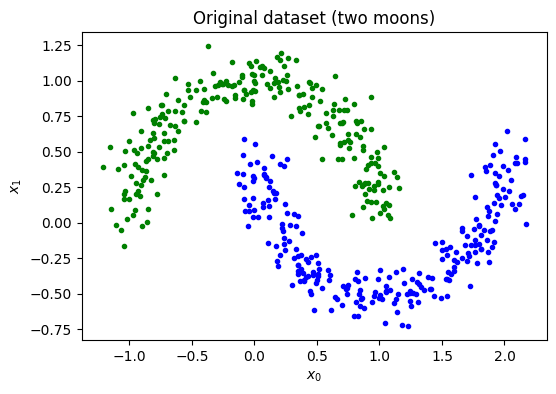

In [2]:
nclasses = 2
measured_qubits = int(np.ceil(np.log2(nclasses)))
nqubits  = 2
nlayers  = 4

# `nshots` is unused in this notebook: every prediction is computed exactly
# from the state vector via `expectation_from_state(...)` (i.e. simulation,
# no sampling). It would be the number of measurement shots on real hardware.
nshots = 10000

num_inputs  = 2
num_samples = 500
X, y = make_moons(num_samples, noise=0.1, random_state=42)

plt.figure(figsize=(6, 4))
for x, y_target in zip(X, y):
    if y_target == 1:
        plt.plot(x[0], x[1], "bo", markersize=3)
    else:
        plt.plot(x[0], x[1], "go", markersize=3)
plt.title("Original dataset (two moons)")
plt.xlabel("$x_0$"); plt.ylabel("$x_1$")
plt.savefig('figures/case1-twomoons.png', dpi=150, bbox_inches='tight'); plt.show()

---
## 3. Preprocessing

### Why rescale to $[-\pi, \pi]$?

The original data range from approximately $-1$ to $2$. Since we encode them as **rotation angles**, we need them to cover a significant range within $[-\pi, \pi]$. The scaling formula:

$$x_{\text{scaled}} = \frac{(2x - x_{\max} - x_{\min}) \cdot \pi}{x_{\max} - x_{\min}}$$

### Labels $\{0,1\} \to \{-1,+1\}$

We convert labels to match the range of $\langle Z \rangle$.

In [3]:
def process_data(data, ref_min=None, ref_max=None):
    '''Rescales data to the range [-pi, pi].'''
    data = np.array(data)
    Min = data.min(axis=0) if ref_min is None else np.array(ref_min)
    Max = data.max(axis=0) if ref_max is None else np.array(ref_max)
    data = (2 * data - Max - Min) * np.pi / (Max - Min)
    return data

Y = 2 * y - np.ones(len(y))  # Labels: {0,1} -> {-1,+1}


---
## 4. Train / Validation / Test Split

We split the data into **70% training / 15% validation / 15% test**. The
training set drives gradient updates, the validation set is used to track
overfitting and to pick the best checkpoint during multi-seed runs, and the
test set is held out for the final number reported in the summary table.

Train: 350 samples  |  Val: 75 samples  |  Test: 75 samples


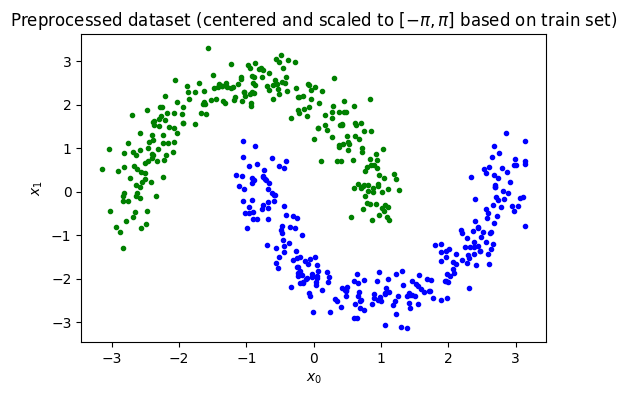

In [4]:
np.random.seed(42)
num_samples = len(Y)
num_train = int(0.70 * num_samples)
num_val = int(0.15 * num_samples)

index = np.random.permutation(range(num_samples))
train_idx = index[:num_train]
val_idx = index[num_train:num_train+num_val]
test_idx = index[num_train+num_val:]

Y_train = Y[train_idx]
Y_val = Y[val_idx]
Y_test = Y[test_idx]

X_train_raw = X[train_idx]
X_min = X_train_raw.min(axis=0)
X_max = X_train_raw.max(axis=0)

X_pad = process_data(X, ref_min=X_min, ref_max=X_max)
X_train = X_pad[train_idx]
X_val = X_pad[val_idx]
X_test = X_pad[test_idx]

print(f"Train: {len(Y_train)} samples  |  Val: {len(Y_val)} samples  |  Test: {len(Y_test)} samples")

plt.figure(figsize=(6, 4))
for x, y_target in zip(X_pad, y):
    if y_target == 1:
        plt.plot(x[0], x[1], "bo", markersize=3)
    else:
        plt.plot(x[0], x[1], "go", markersize=3)
plt.title(r"Preprocessed dataset (centered and scaled to $[-\pi, \pi]$ based on train set)")
plt.xlabel("$x_0$"); plt.ylabel("$x_1$")
plt.show()

---
## 5. Circuit Definitions

We define three circuit architectures. The first two share the same variational layers but differ in how data is injected.

### 5a. VQC with Fixed Encoding (Standard)

Data $(x_0, x_1)$ are injected **directly** as rotation angles: $\theta = x_j$. This is the standard approach in quantum machine learning.

- **Block 1 — Fixed Encoding**: 4 gates, no trainable parameters.
- **Block 2 — Variational Layers**: each of the 4 layers has 2 RY + CZ + 2 RY = 4 parameters per layer, totalling 16 parameters.
- **Block 3 — Final Rotation**: 2 parameters.

**Total: 18 trainable parameters.**

### 5b. VQC with Trainable Encoding (Advanced)

Data is injected as $\theta = w_k \cdot x_j$, where $w_k$ is a **trainable weight**. This allows the model to learn how to scale and weight input features — an advanced technique that increases expressivity at the cost of 4 additional parameters.

**Total: 22 trainable parameters.**

### 5c. Data Reuploading (1 qubit)

| VQC (2 qubits) | Data Reuploading (1 qubit) |
|---|---|
| Data encoded **once** at the beginning | Data **re-injected at every layer** |
| 2 qubits with entanglement | Single qubit, no entanglement |

Angles are **additive**: $\theta = w + x$. A single qubit with data reuploading has **universal classification** capacity.

**Total: 6 trainable parameters.**

In [5]:
def create_circuit_fixed(w, x, nqubits=2, nlayers=4):
    '''VQC with FIXED encoding: theta = x_j directly.
    w has 18 parameters: w[0..15] variational, w[16..17] final.'''
    c = Circuit(nqubits=nqubits)

    # Block 1: Fixed Encoding (no trainable weights)
    c.add(gates.RY(q=0, theta=x[0]))
    c.add(gates.RY(q=1, theta=x[0]))
    c.add(gates.RZ(q=0, theta=x[1]))
    c.add(gates.RZ(q=1, theta=x[1]))

    # Block 2: Variational Layers (w[0]..w[15])
    for i in range(nlayers):
        j = i * 4
        c.add(gates.RY(q=0, theta=w[j]))
        c.add(gates.RY(q=1, theta=w[j + 1]))
        c.add(gates.CZ(0, 1))
        c.add(gates.RY(q=0, theta=w[j + 2]))
        c.add(gates.RY(q=1, theta=w[j + 3]))

    # Block 3: Final Rotation (w[16], w[17])
    c.add(gates.RY(q=0, theta=w[16]))
    c.add(gates.RY(q=1, theta=w[17]))

    c.add(gates.M(0))
    return c


def create_circuit_trainable(w, x, nqubits=2, nlayers=4):
    '''VQC with TRAINABLE encoding: theta = w_k * x_j.
    w has 22 parameters: w[0..3] encoding, w[4..19] variational, w[20..21] final.'''
    c = Circuit(nqubits=nqubits)

    # Block 1: Trainable Encoding (theta = w_k * x_j)
    c.add(gates.RY(q=0, theta=w[0] * x[0]))
    c.add(gates.RY(q=1, theta=w[1] * x[0]))
    c.add(gates.RZ(q=0, theta=w[2] * x[1]))
    c.add(gates.RZ(q=1, theta=w[3] * x[1]))

    # Block 2: Variational Layers (w[4]..w[19])
    for i in range(nlayers):
        j = i * 4 + 3
        c.add(gates.RY(q=0, theta=w[j + 1]))
        c.add(gates.RY(q=1, theta=w[j + 2]))
        c.add(gates.CZ(0, 1))
        c.add(gates.RY(q=0, theta=w[j + 3]))
        c.add(gates.RY(q=1, theta=w[j + 4]))

    # Block 3: Final Rotation (w[20], w[21])
    j_final = nlayers * 4 + 3
    c.add(gates.RY(q=0, theta=w[j_final + 1]))
    c.add(gates.RY(q=1, theta=w[j_final + 2]))

    c.add(gates.M(0))
    return c


def create_circuit_dr(w, x, nqubits=1, nlayers=3):
    '''Data reuploading circuit: 1 qubit, data re-injected every layer (additive).'''
    c = Circuit(nqubits=nqubits)
    for i in range(nlayers):
        c.add(gates.RY(q=0, theta=x[0] + w[2 * i]))
        c.add(gates.RZ(q=0, theta=x[1] + w[2 * i + 1]))
    c.add(gates.M(0))
    return c


# --- Encoding-only circuits (no variational layers, no measurement) ---
# Used to inspect the state at the INPUT of the variational block.
# They answer: "is the ansatz doing something or is the encoding alone
# separating the classes?"

def create_circuit_fixed_encoding_only(x, nqubits=2):
    '''Only the (parameter-free) fixed encoding block.'''
    c = Circuit(nqubits=nqubits)
    c.add(gates.RY(q=0, theta=x[0]))
    c.add(gates.RY(q=1, theta=x[0]))
    c.add(gates.RZ(q=0, theta=x[1]))
    c.add(gates.RZ(q=1, theta=x[1]))
    return c


def create_circuit_trainable_encoding_only(w, x, nqubits=2):
    '''Only the trainable encoding block (theta = w_k * x_j). Uses w[0..3].'''
    c = Circuit(nqubits=nqubits)
    c.add(gates.RY(q=0, theta=w[0] * x[0]))
    c.add(gates.RY(q=1, theta=w[1] * x[0]))
    c.add(gates.RZ(q=0, theta=w[2] * x[1]))
    c.add(gates.RZ(q=1, theta=w[3] * x[1]))
    return c


In [6]:
# =============================================================================
# Fast NumPy circuit forwards
# =============================================================================
# The full implementations of fast_vqc_fixed_states, fast_vqc_trainable_states,
# fast_dr_states, the encoding-only variants, fast_z0, fast_states, fast_predict,
# and the Bloch-coordinate helpers state_to_bloch / state_to_bloch_batch were
# extracted to qml_core.py and imported in Cell 3 (the imports cell at the top
# of the notebook). Conventions are unchanged:
#
#   * State ordering big-endian: |q0 q1> -> state[2*q0 + q1]
#   * RY(theta) = exp(-i theta Y / 2);  RZ(theta) = exp(-i theta Z / 2)
#   * CZ control=q0, target=q1 -> diag(1, 1, 1, -1)
#
# Function signatures are exactly as before; the rest of the notebook
# (training loops, Bloch visualisation, decision-boundary plots) calls them
# without any changes.

print("Quantum core: imported from qml_core")
print("  - fast_vqc_fixed_states, fast_vqc_trainable_states, fast_dr_states")
print("  - fast_fixed_encoding_states, fast_trainable_encoding_states")
print("  - fast_z0, fast_states, fast_predict")
print("  - state_to_bloch, state_to_bloch_batch")


Quantum core: imported from qml_core
  - fast_vqc_fixed_states, fast_vqc_trainable_states, fast_dr_states
  - fast_fixed_encoding_states, fast_trainable_encoding_states
  - fast_z0, fast_states, fast_predict
  - state_to_bloch, state_to_bloch_batch


### VQC Circuit Diagram (2 qubits, 4 layers)

Read **left to right**: each horizontal line is a qubit (q0 on top, q1 below). Boxes are quantum gates, vertical lines represent 2-qubit entanglement (CZ). For fixed encoding, the green boxes contain $x_j$ directly; for trainable encoding they contain $w_k \cdot x_j$.

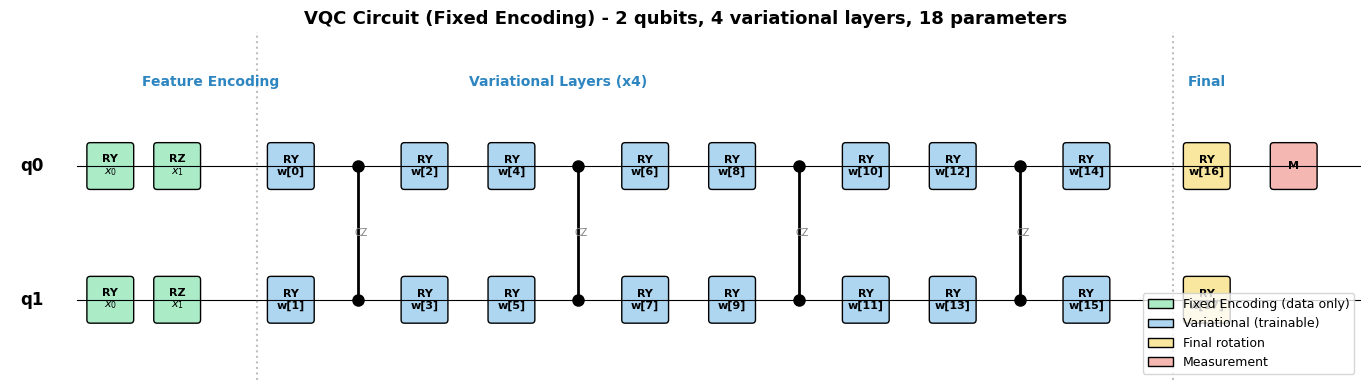


Qibo circuit structure (text):
0: ─RY─RZ─RY─o─RY─RY─o─RY─RY─o─RY─RY─o─RY─RY─M─
1: ─RY─RZ─RY─Z─RY─RY─Z─RY─RY─Z─RY─RY─Z─RY─RY───
None


In [7]:
def draw_vqc_circuit(nqubits=2, nlayers=4, figsize=(22, 4)):
    fig, ax = plt.subplots(figsize=figsize)
    qubit_y = {0: 2, 1: 0}
    gate_width, gate_height = 0.6, 0.6
    x_pos, x_step = 0.5, 1.0
    total_width = 4 + nlayers * 5 + 3
    for q in range(nqubits):
        ax.plot([0, total_width * x_step], [qubit_y[q], qubit_y[q]], 'k-', linewidth=0.8)
        ax.text(-0.5, qubit_y[q], f'q{q}', fontsize=12, ha='right', va='center', fontweight='bold')
    def draw_gate(x, y, label, color='#AED6F1', fontsize=8):
        rect = mpatches.FancyBboxPatch((x-gate_width/2, y-gate_height/2), gate_width, gate_height,
                                         boxstyle="round,pad=0.05", facecolor=color, edgecolor='black', linewidth=1)
        ax.add_patch(rect)
        ax.text(x, y, label, fontsize=fontsize, ha='center', va='center', fontweight='bold')
    def draw_cz(x, y0, y1):
        ax.plot([x, x], [y0, y1], 'k-', linewidth=2)
        ax.plot(x, y0, 'ko', markersize=8); ax.plot(x, y1, 'ko', markersize=8)
    ax.annotate('Feature Encoding', xy=(x_pos+1.5*x_step, 3.2), fontsize=10, ha='center', color='#2E86C1', fontweight='bold')
    draw_gate(x_pos, qubit_y[0], 'RY\n$x_0$', color='#ABEBC6')
    draw_gate(x_pos, qubit_y[1], 'RY\n$x_0$', color='#ABEBC6')
    x_pos += x_step
    draw_gate(x_pos, qubit_y[0], 'RZ\n$x_1$', color='#ABEBC6')
    draw_gate(x_pos, qubit_y[1], 'RZ\n$x_1$', color='#ABEBC6')
    x_pos += x_step*1.2; ax.axvline(x=x_pos, color='gray', linestyle=':', alpha=0.5); x_pos += x_step*0.5
    ax.annotate('Variational Layers (x4)', xy=(x_pos+4*x_step, 3.2), fontsize=10, ha='center', color='#2E86C1', fontweight='bold')
    for layer in range(nlayers):
        if layer > 0: x_pos += x_step*0.3
        j = layer*4
        draw_gate(x_pos, qubit_y[0], f'RY\nw[{j}]', color='#AED6F1')
        draw_gate(x_pos, qubit_y[1], f'RY\nw[{j+1}]', color='#AED6F1'); x_pos += x_step
        draw_cz(x_pos, qubit_y[0], qubit_y[1])
        ax.text(x_pos+0.05, 1, 'CZ', fontsize=7, ha='center', va='center', color='gray'); x_pos += x_step
        draw_gate(x_pos, qubit_y[0], f'RY\nw[{j+2}]', color='#AED6F1')
        draw_gate(x_pos, qubit_y[1], f'RY\nw[{j+3}]', color='#AED6F1'); x_pos += x_step
    x_pos += x_step*0.3; ax.axvline(x=x_pos, color='gray', linestyle=':', alpha=0.5); x_pos += x_step*0.5
    ax.annotate('Final', xy=(x_pos, 3.2), fontsize=10, ha='center', color='#2E86C1', fontweight='bold')
    draw_gate(x_pos, qubit_y[0], 'RY\nw[16]', color='#F9E79F')
    draw_gate(x_pos, qubit_y[1], 'RY\nw[17]', color='#F9E79F'); x_pos += x_step*1.3
    draw_gate(x_pos, qubit_y[0], 'M', color='#F5B7B1')
    legend_elements = [mpatches.Patch(facecolor='#ABEBC6', edgecolor='black', label='Fixed Encoding (data only)'),
        mpatches.Patch(facecolor='#AED6F1', edgecolor='black', label='Variational (trainable)'),
        mpatches.Patch(facecolor='#F9E79F', edgecolor='black', label='Final rotation'),
        mpatches.Patch(facecolor='#F5B7B1', edgecolor='black', label='Measurement')]
    ax.legend(handles=legend_elements, loc='lower right', fontsize=9)
    ax.set_xlim(-1, x_pos+1); ax.set_ylim(-1.2, 4); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title('VQC Circuit (Fixed Encoding) - 2 qubits, 4 variational layers, 18 parameters', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.savefig('figures/case1-circuit-vqc.png', dpi=150, bbox_inches='tight'); plt.show()

draw_vqc_circuit()
print("\nQibo circuit structure (text):")
print(create_circuit_fixed(np.zeros(18), np.array([1.0, 1.0])).draw())

### Data Reuploading Circuit Diagram (1 qubit, 3 layers)

Only **one line** (1 qubit) and data re-introduced at **every layer**.

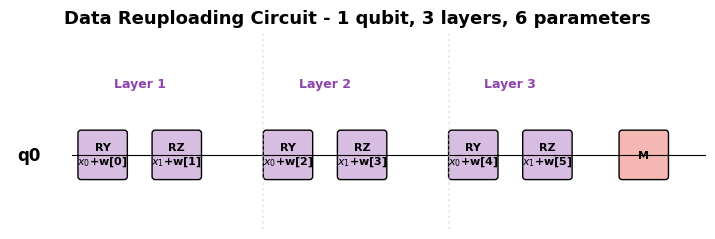


Qibo circuit structure:
0: ─RY─RZ─RY─RZ─RY─RZ─M─
None


In [8]:
def draw_dr_circuit(nlayers=3, figsize=(16, 2.5)):
    fig, ax = plt.subplots(figsize=figsize)
    qubit_y = 0; gate_width, gate_height = 0.7, 0.7; x_pos, x_step = 0.5, 1.2
    total_width = nlayers * 3 * x_step + 3
    ax.plot([0, total_width], [qubit_y, qubit_y], 'k-', linewidth=0.8)
    ax.text(-0.5, qubit_y, 'q0', fontsize=12, ha='right', va='center', fontweight='bold')
    def draw_gate(x, y, label, color='#AED6F1', fontsize=8):
        rect = mpatches.FancyBboxPatch((x-gate_width/2, y-gate_height/2), gate_width, gate_height,
                                         boxstyle="round,pad=0.05", facecolor=color, edgecolor='black', linewidth=1)
        ax.add_patch(rect)
        ax.text(x, y, label, fontsize=fontsize, ha='center', va='center', fontweight='bold')
    for layer in range(nlayers):
        ax.annotate(f'Layer {layer+1}', xy=(x_pos+0.5*x_step, 1.1), fontsize=9, ha='center', color='#8E44AD', fontweight='bold')
        draw_gate(x_pos, qubit_y, f'RY\n$x_0$+w[{2*layer}]', color='#D7BDE2'); x_pos += x_step
        draw_gate(x_pos, qubit_y, f'RZ\n$x_1$+w[{2*layer+1}]', color='#D7BDE2'); x_pos += x_step
        if layer < nlayers-1: ax.axvline(x=x_pos+0.2, color='lightgray', linestyle=':', alpha=0.5); x_pos += x_step*0.5
    x_pos += x_step*0.3
    draw_gate(x_pos, qubit_y, 'M', color='#F5B7B1')
    ax.set_xlim(-1, x_pos+1); ax.set_ylim(-1.2, 2); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title('Data Reuploading Circuit - 1 qubit, 3 layers, 6 parameters', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.savefig('figures/case1-circuit-dr.png', dpi=150, bbox_inches='tight'); plt.show()

draw_dr_circuit()
print("\nQibo circuit structure:")
print(create_circuit_dr(np.zeros(6), np.array([1.0, 1.0])).draw())

---
## 6. Hamiltonian and Predictions

We measure Pauli-Z on the first qubit: $\langle Z \rangle \in [-1, +1]$ is our prediction. The computation uses `expectation_from_state()` which is **analytically exact** (no statistical noise).

In [9]:
_hamiltonian_cache = {}

def hamiltonian(nqubits):
    '''Defines the measurement observable. 1 qubit: Z. 2 qubits: Z (x) I.
    Cached because re-creating the SymbolicHamiltonian on every prediction
    is pure overhead during training.'''
    if nqubits not in _hamiltonian_cache:
        Obj = Z(0) if nqubits == 1 else Z(0) * I(1)
        _hamiltonian_cache[nqubits] = hamiltonians.SymbolicHamiltonian(Obj)
    return _hamiltonian_cache[nqubits]


def Predictions(data, theta, nqubits, nshots=10000, circuit_type='fixed'):
    '''Single-point prediction through the Qibo backend (used by the
    autodifferentiation training loop only). Bumps the shared circuit-eval
    counter in qml_core so AD and PS eval counts can be compared on the
    same axis.'''
    bump_counter(1)
    if circuit_type == 'dr':
        c = create_circuit_dr(theta, data, nqubits)
    elif circuit_type == 'trainable':
        c = create_circuit_trainable(theta, data, nqubits)
    else:
        c = create_circuit_fixed(theta, data, nqubits)
    h = hamiltonian(nqubits)
    return h.expectation_from_state(c.execute().state())


---
## 7. Cost Function and Accuracy

### Square Loss

$$\text{Square Loss} = \frac{1}{N}\sum_{i=1}^N (y_i - \hat{y}_i)^2$$

### Accuracy

Does the **sign** of the prediction match the label? Percentage of correct classifications.

In [10]:
def _to_float(x):
    '''Safely convert a scalar (torch tensor, numpy, or python number) to a python float.'''
    if hasattr(x, 'detach'):
        return float(x.detach().cpu().real)
    return float(np.real(x))


def sqloss_acc(labels, predictions, verbose=True):
    '''Computes square loss and accuracy.'''
    sqloss = 0
    acc = 0
    for label, prediction in zip(labels, predictions):
        sqloss = sqloss + (label - prediction) ** 2
        if np.sign(label) == np.sign(_to_float(prediction)):
            acc += 1
    sqloss = sqloss / len(labels)
    acc = acc / len(labels)
    if verbose:
        print(f'  Loss: {_to_float(sqloss):.4f}  |  Acc: {acc:.4f}')
    return sqloss, acc


def Cost_function(theta, data, Y, nqubits, nshots=10000, circuit_type='fixed', verbose=True):
    '''Evaluates the model on an entire dataset.'''
    predictions = [Predictions(x, theta, nqubits, nshots, circuit_type=circuit_type) for x in data]
    return sqloss_acc(Y, predictions, verbose)

In [11]:
# Counter helpers (reset_counter / get_counter / bump_counter) are imported
# from qml_core; the Qibo-path Predictions in Cell 18 calls bump_counter to
# share the same eval-count source of truth with the parameter-shift path.
# This cell is intentionally a no-op; it documents the dependency.


---
## 8. Bloch Sphere Visualization Tools

The Bloch sphere is the natural representation of a single-qubit state. For a 2-qubit system, we compute the **reduced density matrix** via partial trace to obtain the effective single-qubit state for each qubit independently.

For a state $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$, the Bloch vector is:

$$x = 2\,\text{Re}(\rho_{01}), \quad y = 2\,\text{Im}(\rho_{10}), \quad z = \rho_{00} - \rho_{11}$$

where $\rho$ is the (reduced) density matrix. For a 2-qubit state $|\psi\rangle$, the reduced density matrix of qubit $k$ is obtained by tracing out the other qubit.

In [12]:
# state_to_bloch and state_to_bloch_batch are imported from qml_core.


def draw_bloch_sphere(ax, title='', alpha_sphere=0.08):
    '''Draw a wireframe Bloch sphere on a 3D axis.'''
    u = np.linspace(0, 2 * np.pi, 40)
    v = np.linspace(0, np.pi, 20)
    xs = np.outer(np.cos(u), np.sin(v))
    ys = np.outer(np.sin(u), np.sin(v))
    zs = np.outer(np.ones(np.size(u)), np.cos(v))
    ax.plot_wireframe(xs, ys, zs, color='gray', alpha=alpha_sphere, linewidth=0.3)

    ax.plot([-1.2, 1.2], [0, 0], [0, 0], 'k-', alpha=0.2, linewidth=0.5)
    ax.plot([0, 0], [-1.2, 1.2], [0, 0], 'k-', alpha=0.2, linewidth=0.5)
    ax.plot([0, 0], [0, 0], [-1.2, 1.2], 'k-', alpha=0.2, linewidth=0.5)

    ax.text(0, 0, 1.35, r'$|0\rangle$', fontsize=10, ha='center', fontweight='bold')
    ax.text(0, 0, -1.35, r'$|1\rangle$', fontsize=10, ha='center', fontweight='bold')
    ax.text(1.35, 0, 0, 'X', fontsize=8, ha='center', alpha=0.5)
    ax.text(0, 1.35, 0, 'Y', fontsize=8, ha='center', alpha=0.5)

    ax.set_xlim([-1.3, 1.3]); ax.set_ylim([-1.3, 1.3]); ax.set_zlim([-1.3, 1.3])
    ax.set_box_aspect([1, 1, 1])
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=11, fontweight='bold', pad=10)


def get_circuit_state_np(theta, data_point, nqubits, circuit_type='fixed'):
    '''Run circuit (fast numpy path) and return the state vector for ONE data point.'''
    states = fast_states(np.asarray(theta), np.atleast_2d(data_point), circuit_type=circuit_type)
    return states[0]


def precompute_bloch(params_history, X_samples, nqubits, circuit_type='fixed'):
    '''Pre-compute Bloch vectors for every (iteration, sample) using batched
    fast numpy forwards. One batched forward per iteration.'''
    n_iters = len(params_history)
    n_samples = len(X_samples)
    result = {f'q{q}': np.zeros((n_iters, n_samples, 3)) for q in range(nqubits)}
    X = np.asarray(X_samples)

    for it in range(n_iters):
        if it % 50 == 0:
            print(f'  Computing iteration {it}/{n_iters-1}...')
        states = fast_states(np.asarray(params_history[it]), X, circuit_type=circuit_type)
        for q in range(nqubits):
            result[f'q{q}'][it] = state_to_bloch_batch(states, qubit=q)

    print('  Done.')
    return result


# ---- Plotly Bloch viewer ------------------------------------------------
# Self-contained replacement for the ipywidgets-based Bloch slider. Plotly
# embeds all frame data into the notebook output as JSON, so the
# interactive visualization persists across notebook reopens without
# needing to re-run the kernel (ipywidgets only renders if the kernel is
# alive — that is what produced the 'application/vnd.jupyter.widget-view'
# placeholder when the notebook was reopened).

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def make_bloch_plotly(bloch_data, Y_bloch, nqubits, suptitle, height=720):
    """Return a Plotly figure with a slider scrubbing through training iterations.

    Parameters
    ----------
    bloch_data : dict
        Output of `precompute_bloch`. Keys 'q0' (and 'q1' for nqubits==2),
        each an array of shape (n_iters, n_samples, 3).
    Y_bloch : (n_samples,) array of labels in {-1, +1}.
    nqubits : 1 or 2.
    suptitle : figure title.
    """
    n_iters = bloch_data['q0'].shape[0]
    blue = (np.asarray(Y_bloch) > 0)
    red = ~blue
    qubits = list(range(nqubits))

    if nqubits == 2:
        fig = make_subplots(
            rows=2, cols=2, row_heights=[0.62, 0.38],
            specs=[[{'type': 'scene'}, {'type': 'scene'}],
                   [{'type': 'xy'},    {'type': 'xy'}]],
            subplot_titles=('Qubit 0 — 3D', 'Qubit 1 — 3D',
                            'Qubit 0 — XZ projection', 'Qubit 1 — XZ projection'),
            horizontal_spacing=0.05, vertical_spacing=0.10)
    else:
        fig = make_subplots(
            rows=1, cols=2, column_widths=[0.55, 0.45],
            specs=[[{'type': 'scene'}, {'type': 'xy'}]],
            subplot_titles=('3D Bloch sphere', 'XZ projection — Z = ⟨Z⟩'),
            horizontal_spacing=0.04)

    # ---- Static decorations: wireframe sphere + axes ----
    def _wireframe_xyz():
        u = np.linspace(0, 2 * np.pi, 60)
        v = np.linspace(0, np.pi, 12)
        xs, ys, zs = [], [], []
        # latitudes (skip poles)
        for j in range(1, len(v) - 1):
            xs.extend((np.cos(u) * np.sin(v[j])).tolist() + [None])
            ys.extend((np.sin(u) * np.sin(v[j])).tolist() + [None])
            zs.extend(np.full_like(u, np.cos(v[j])).tolist() + [None])
        # longitudes
        theta = np.linspace(0, 2 * np.pi, 60)
        for phi in np.linspace(0, np.pi, 6, endpoint=False):
            xs.extend((np.cos(phi) * np.sin(theta)).tolist() + [None])
            ys.extend((np.sin(phi) * np.sin(theta)).tolist() + [None])
            zs.extend(np.cos(theta).tolist() + [None])
        return xs, ys, zs

    sx, sy, sz = _wireframe_xyz()

    for q in qubits:
        col = q + 1
        fig.add_trace(go.Scatter3d(x=sx, y=sy, z=sz, mode='lines',
                                   line=dict(color='lightgray', width=1),
                                   hoverinfo='skip', showlegend=False),
                      row=1, col=col)
        fig.add_trace(go.Scatter3d(x=[0, 0], y=[0, 0], z=[1.25, -1.25],
                                   mode='text', text=['|0⟩', '|1⟩'],
                                   textfont=dict(size=14),
                                   hoverinfo='skip', showlegend=False),
                      row=1, col=col)
        fig.add_trace(go.Scatter3d(x=[0, 0], y=[0, 0], z=[-1.05, 1.05],
                                   mode='lines',
                                   line=dict(color='lightgray', width=2),
                                   hoverinfo='skip', showlegend=False),
                      row=1, col=col)

    theta_circ = np.linspace(0, 2 * np.pi, 100)
    for q in qubits:
        # FIX: Ensure 2D plots go to the right subplot coordinates
        row2d = 2 if nqubits == 2 else 1
        col2d = q + 1 if nqubits == 2 else 2 
        
        fig.add_trace(go.Scatter(x=np.cos(theta_circ), y=np.sin(theta_circ),
                                 mode='lines', line=dict(color='gray', width=1),
                                 hoverinfo='skip', showlegend=False),
                      row=row2d, col=col2d)
        fig.add_trace(go.Scatter(x=[-1.4, 1.4], y=[0, 0], mode='lines',
                                 line=dict(color='gray', width=1, dash='dash'),
                                 hoverinfo='skip', showlegend=False),
                      row=row2d, col=col2d)

    static_count = len(fig.data)

    # ---- Dynamic traces (iteration 0) ----
    show_blue, show_red = True, True
    for q in qubits:
        col = q + 1
        bd = bloch_data[f'q{q}'][0]
        bd_b, bd_r = bd[blue], bd[red]
        fig.add_trace(go.Scatter3d(
            x=bd_b[:, 0], y=bd_b[:, 1], z=bd_b[:, 2],
            mode='markers',
            marker=dict(size=4.5, color='#2196F3',
                        line=dict(color='black', width=0.5)),
            name='Class +1', legendgroup='+1',
            showlegend=show_blue, hoverinfo='skip'),
            row=1, col=col)
        show_blue = False
        fig.add_trace(go.Scatter3d(
            x=bd_r[:, 0], y=bd_r[:, 1], z=bd_r[:, 2],
            mode='markers',
            marker=dict(size=4.5, color='#F44336', symbol='diamond',
                        line=dict(color='black', width=0.5)),
            name='Class -1', legendgroup='-1',
            showlegend=show_red, hoverinfo='skip'),
            row=1, col=col)
        show_red = False

    for q in qubits:
        # FIX: Align dynamic 2D traces to the right layout
        row2d = 2 if nqubits == 2 else 1
        col2d = q + 1 if nqubits == 2 else 2
        bd = bloch_data[f'q{q}'][0]
        bd_b, bd_r = bd[blue], bd[red]
        fig.add_trace(go.Scatter(x=bd_b[:, 0], y=bd_b[:, 2],
                                 mode='markers',
                                 marker=dict(size=8, color='#2196F3',
                                             line=dict(color='black', width=0.5)),
                                 showlegend=False, hoverinfo='skip'),
                      row=row2d, col=col2d)
        fig.add_trace(go.Scatter(x=bd_r[:, 0], y=bd_r[:, 2],
                                 mode='markers',
                                 marker=dict(size=8, color='#F44336',
                                             symbol='diamond',
                                             line=dict(color='black', width=0.5)),
                                 showlegend=False, hoverinfo='skip'),
                      row=row2d, col=col2d)

    n_dynamic = len(fig.data) - static_count
    dyn_idx = list(range(static_count, static_count + n_dynamic))

    # ---- Frames ----
    frames = []
    for it in range(n_iters):
        traces_data = []
        for q in qubits:
            bd = bloch_data[f'q{q}'][it]
            bd_b, bd_r = bd[blue], bd[red]
            traces_data.append(go.Scatter3d(x=bd_b[:, 0], y=bd_b[:, 1], z=bd_b[:, 2]))
            traces_data.append(go.Scatter3d(x=bd_r[:, 0], y=bd_r[:, 1], z=bd_r[:, 2]))
        for q in qubits:
            bd = bloch_data[f'q{q}'][it]
            bd_b, bd_r = bd[blue], bd[red]
            traces_data.append(go.Scatter(x=bd_b[:, 0], y=bd_b[:, 2]))
            traces_data.append(go.Scatter(x=bd_r[:, 0], y=bd_r[:, 2]))
        frames.append(go.Frame(data=traces_data, traces=dyn_idx, name=str(it)))
    fig.frames = frames

    # ---- Slider + play/pause ----
    sliders = [dict(
        active=0,
        currentvalue=dict(prefix='Iteration: ', font=dict(size=12)),
        steps=[dict(method='animate', label=str(i),
                    args=[[str(i)],
                          dict(mode='immediate',
                               frame=dict(duration=0, redraw=True),
                               transition=dict(duration=0))])
               for i in range(n_iters)],
        x=0.05, len=0.9, pad=dict(t=20, b=10),
    )]

    play_btn = dict(
        type='buttons', showactive=False,
        x=0.0, y=-0.05, xanchor='left', yanchor='top',
        buttons=[
            dict(label='▶ Play', method='animate',
                 args=[None, dict(frame=dict(duration=80, redraw=True),
                                  fromcurrent=True)]),
            dict(label='■ Pause', method='animate',
                 args=[[None], dict(frame=dict(duration=0, redraw=True),
                                    mode='immediate')])])

    scene_cfg = dict(
        xaxis=dict(showticklabels=False, range=[-1.3, 1.3], showgrid=False,
                   zeroline=False, title=''),
        yaxis=dict(showticklabels=False, range=[-1.3, 1.3], showgrid=False,
                   zeroline=False, title=''),
        zaxis=dict(showticklabels=False, range=[-1.3, 1.3], showgrid=False,
                   zeroline=False, title=''),
        aspectmode='cube',
        camera=dict(eye=dict(x=1.4, y=1.4, z=0.7)))

    layout = dict(
        title=dict(text=suptitle, x=0.5, font=dict(size=14)),
        height=height, sliders=sliders, updatemenus=[play_btn],
        margin=dict(l=20, r=20, t=70, b=70),
        legend=dict(orientation='h', x=0.5, xanchor='center',
                    y=-0.02, yanchor='top'),
        scene=scene_cfg)
    if nqubits == 2:
        layout['scene2'] = scene_cfg
    fig.update_layout(**layout)

    for q in qubits:
        # FIX: Align axes updates to the correct layout
        row2d = 2 if nqubits == 2 else 1
        col2d = q + 1 if nqubits == 2 else 2
        fig.update_xaxes(range=[-1.4, 1.4], row=row2d, col=col2d,
                         title='X', zeroline=False, showgrid=False)
        fig.update_yaxes(range=[-1.4, 1.4], row=row2d, col=col2d,
                         title='Z', zeroline=False, showgrid=False,
                         scaleanchor='x', scaleratio=1)

    return fig


# Sample data points for Bloch visualization
np.random.seed(42)
n_bloch_samples = 50
sample_idx = np.random.choice(len(X_pad), n_bloch_samples, replace=False)
X_bloch = X_pad[sample_idx]
Y_bloch = Y[sample_idx]
print(f"Bloch sample: {n_bloch_samples} points selected.")


Bloch sample: 50 points selected.


---
## 9. Optimization and Gradient Tools

### Adam Optimizer

We implement Adam in pure NumPy so that both the autodiff and parameter-shift pipelines use **identical optimization dynamics**. During autodiff, the gradient is extracted from PyTorch and fed into this optimizer.

### Parameter-Shift Rule

$$\frac{\partial \langle O \rangle}{\partial \theta_k} = \frac{\langle O \rangle_{\theta_k + \pi/2} - \langle O \rangle_{\theta_k - \pi/2}}{2}$$

For trainable encoding parameters (multiplicative $w \cdot x$), the shift must be adapted using the chain rule (data-dependent shift). For all other parameters (standard rotations), the $\pi/2$ shift is used directly.

In [13]:
# =============================================================================
# Adam optimiser, parameter-shift gradient, training runner
# =============================================================================
# All training primitives now live in qml_core and are imported in Cell 3:
#
#     AdamOptimizer            -> shared by AD and PS so both pipelines use
#                                 identical optimiser dynamics
#     parameter_shift_gradient -> vectorised PS, with optional sample_weight
#     cost_np                  -> forward-only weighted MSE
#     train_ps_run             -> single training run, configurable selection
#                                 criterion (val_loss or val_acc)
#     train_ps_multi_seed      -> multi-seed exploration with best-by-val
#                                 checkpoint
#
# This notebook uses select_by='val_acc' (with tiebreak on lower val_loss)
# in its multi-seed exploration cells, matching the original notebook's
# selection rule. Case Study 2 of the thesis (the imbalance grid) uses
# select_by='val_loss' instead because val is balanced and loss is the
# smoother criterion -- see Section 3.5 of the thesis for the rationale.

print("Training primitives: imported from qml_core")
print("  - AdamOptimizer, parameter_shift_gradient, cost_np")
print("  - train_ps_run (select_by='val_loss' default; pass 'val_acc' below)")
print("  - train_ps_multi_seed")


Training primitives: imported from qml_core
  - AdamOptimizer, parameter_shift_gradient, cost_np
  - train_ps_run (select_by='val_loss' default; pass 'val_acc' below)
  - train_ps_multi_seed


---
---

# Part 1: VQC with Fixed Encoding (Standard Approach)

In this part we train the 2-qubit VQC using **fixed angle encoding**: data is injected as $\theta = x_j$ directly, with **no trainable parameters** in the encoding block. This is the standard approach in quantum machine learning.

The model has **18 trainable parameters** (16 variational + 2 final).

We train with both gradient methods and compare.

---
## 10. Parameter Initialization (Fixed Encoding)

The 18 parameters are initialized randomly in $[0, \pi]$.

In [14]:
qibo.set_backend("qiboml", platform="pytorch")

nparams_fixed = 2 * nqubits * nlayers + nqubits  # 16 + 2 = 18
print(f'Number of parameters (fixed encoding): {nparams_fixed}')

np.random.seed(0)
params_np_fixed_ad = np.pi * np.random.rand(nparams_fixed).copy()
print('Initial parameters:', params_np_fixed_ad)

params_torch = torch.tensor(params_np_fixed_ad, dtype=torch.complex128)
print('\nInitial cost (full dataset):')
_ = Cost_function(params_torch, X_pad, Y, nqubits, circuit_type='fixed')

[Qibo 0.2.23|INFO|2026-05-26 10:11:53]: Using qiboml (pytorch) backend on cuda:0


Number of parameters (fixed encoding): 18
Initial parameters: [1.72414847 2.24683366 1.89363699 1.711801   1.33095081 2.0291362
 1.37472077 2.80158751 3.02743585 1.20461706 2.48727756 1.66157239
 1.78456462 2.9078476  0.22316636 0.27372477 0.06351797 2.61575239]

Initial cost (full dataset):
  Loss: 1.5818  |  Acc: 0.4800


---
## 11. Training Loop — Autodifferentiation (PyTorch)

### What happens at each iteration?

1. **Snapshot**: parameter copy saved BEFORE updating (for plotting evolution).
2. **Forward pass**: PyTorch records all operations in a computational graph.
3. **Backward pass**: `loss.backward()` computes $\partial \mathcal{L}/\partial w_k$ via the chain rule.
4. **Gradient extraction**: we extract the real part of the gradient (the quantum backend uses complex tensors internally).
5. **Adam update**: parameters are modified to reduce loss.

### Gradient norm $\|\nabla \mathcal{L}\|$

$$\|\nabla \mathcal{L}\| = \sqrt{\sum_{k=1}^{18} \left(\frac{\partial \mathcal{L}}{\partial w_k}\right)^2}$$

| Value | Meaning |
|---|---|
| **Large** | Loss can be reduced significantly — steep slope |
| **Small but > 0** | Near the minimum, fine-tuning |
| **$\approx 0$** | Converged (good) or *barren plateau* (bad) |

In [15]:
qibo.set_backend("qiboml", platform="pytorch")

start_time = time()
n_iter = 200
learning_rate = 0.015
optimizer_ad = AdamOptimizer(learning_rate=learning_rate, beta1=0.9, beta2=0.999, epsilon=1e-8)

np.random.seed(0)
params_np_fixed_ad = np.pi * np.random.rand(nparams_fixed).copy()

history_fixed_ad = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'params': [], 'grad_norms': []}
reset_counter()

for it in range(n_iter):
    print(f'\n=== Iteration {it} ===')
    history_fixed_ad['params'].append(params_np_fixed_ad.copy())

    params_torch = torch.tensor(params_np_fixed_ad, dtype=torch.complex128, requires_grad=True)
    result = Cost_function(params_torch, X_train, Y_train, nqubits, verbose=False, circuit_type='fixed')
    train_loss = result[0]; train_acc = result[1]
    train_loss.backward()

    real_grad = params_torch.grad.real.detach().cpu().numpy().copy()
    grad_norm = float(np.linalg.norm(real_grad))
    history_fixed_ad['grad_norms'].append(grad_norm)

    with torch.no_grad():
        val_result = Cost_function(params_torch, X_val, Y_val, nqubits, verbose=False, circuit_type='fixed')

    history_fixed_ad['train_loss'].append(_to_float(train_loss))
    history_fixed_ad['train_acc'].append(float(train_acc))
    history_fixed_ad['val_loss'].append(_to_float(val_result[0]))
    history_fixed_ad['val_acc'].append(float(val_result[1]))

    params_np_fixed_ad = optimizer_ad.step(params_np_fixed_ad, real_grad)
    print(f'  Train Loss: {history_fixed_ad["train_loss"][-1]:.4f}  |  Acc: {history_fixed_ad["train_acc"][-1]:.4f}')
    print(f'  Val   Loss: {history_fixed_ad["val_loss"][-1]:.4f}  |  Acc: {history_fixed_ad["val_acc"][-1]:.4f}')
    print(f'  ||grad||: {grad_norm:.6f}')

print('\n-- Final cost (test dataset) --')
params_final = torch.tensor(params_np_fixed_ad, dtype=torch.complex128)
Cost_function(params_final, X_test, Y_test, nqubits, circuit_type='fixed')
history_fixed_ad['params'].append(params_np_fixed_ad.copy())
autodiff_time = (time()-start_time)/60
autodiff_evals = get_counter()
print(f'\nTraining time: {autodiff_time:.2f} minutes')
print(f'Total circuit evaluations: {autodiff_evals:,}')

[Qibo 0.2.23|INFO|2026-05-26 10:11:58]: Using qiboml (pytorch) backend on cuda:0



=== Iteration 0 ===
  Train Loss: 1.6090  |  Acc: 0.4629
  Val   Loss: 1.4522  |  Acc: 0.5333
  ||grad||: 1.198816

=== Iteration 1 ===
  Train Loss: 1.5495  |  Acc: 0.4743
  Val   Loss: 1.4004  |  Acc: 0.5600
  ||grad||: 1.340561

=== Iteration 2 ===
  Train Loss: 1.4818  |  Acc: 0.4914
  Val   Loss: 1.3421  |  Acc: 0.5733
  ||grad||: 1.466010

=== Iteration 3 ===
  Train Loss: 1.4073  |  Acc: 0.5057
  Val   Loss: 1.2784  |  Acc: 0.5867
  ||grad||: 1.565730

=== Iteration 4 ===
  Train Loss: 1.3275  |  Acc: 0.5229
  Val   Loss: 1.2105  |  Acc: 0.6267
  ||grad||: 1.632974

=== Iteration 5 ===
  Train Loss: 1.2438  |  Acc: 0.5457
  Val   Loss: 1.1396  |  Acc: 0.6400
  ||grad||: 1.660192

=== Iteration 6 ===
  Train Loss: 1.1585  |  Acc: 0.5571
  Val   Loss: 1.0678  |  Acc: 0.6533
  ||grad||: 1.638490

=== Iteration 7 ===
  Train Loss: 1.0748  |  Acc: 0.5914
  Val   Loss: 0.9978  |  Acc: 0.6667
  ||grad||: 1.562879

=== Iteration 8 ===
  Train Loss: 0.9962  |  Acc: 0.6114
  Val   Loss: 

---
## 12. Training Curves: Loss, Accuracy and Gradient

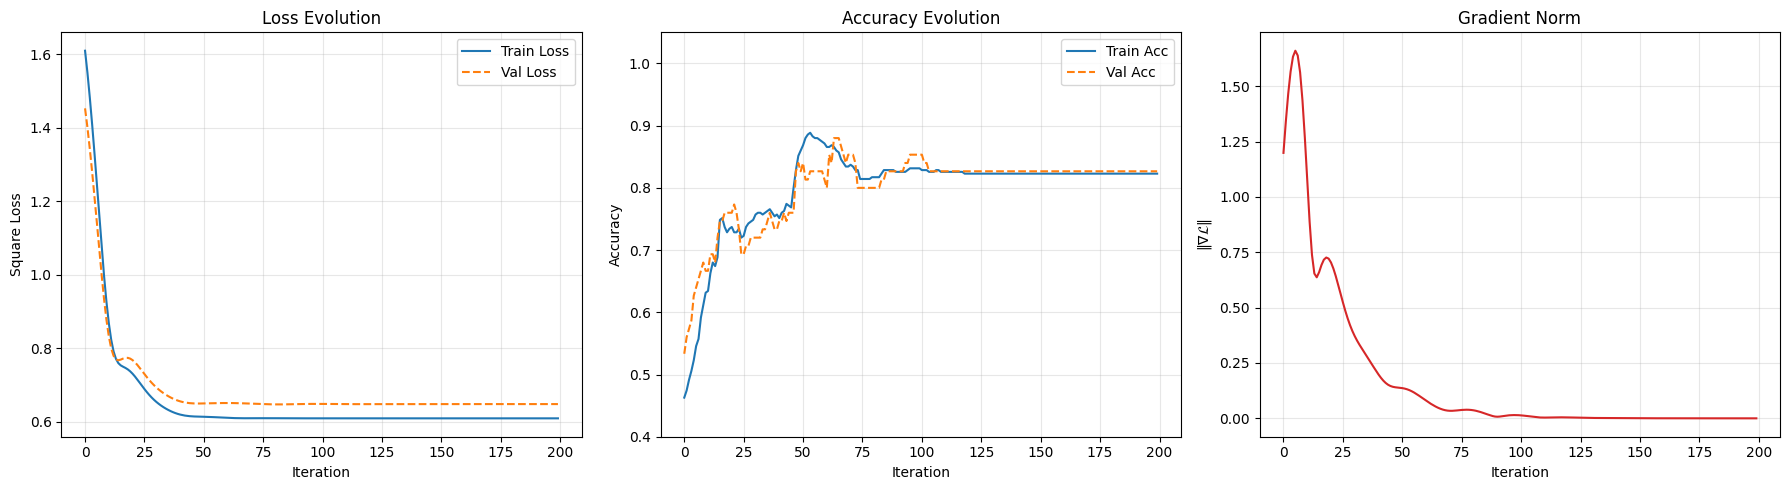

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(history_fixed_ad['train_loss'], label='Train Loss', color='tab:blue')
axes[0].plot(history_fixed_ad['val_loss'], label='Val Loss', color='tab:orange', linestyle='--')
axes[0].set_xlabel('Iteration'); axes[0].set_ylabel('Square Loss')
axes[0].set_title('Loss Evolution'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(history_fixed_ad['train_acc'], label='Train Acc', color='tab:blue')
axes[1].plot(history_fixed_ad['val_acc'], label='Val Acc', color='tab:orange', linestyle='--')
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy Evolution'); axes[1].legend(); axes[1].grid(True, alpha=0.3); axes[1].set_ylim([0.4, 1.05])
axes[2].plot(history_fixed_ad['grad_norms'], color='tab:red')
axes[2].set_xlabel('Iteration'); axes[2].set_ylabel('$\\|\\nabla \\mathcal{L}\\|$')
axes[2].set_title('Gradient Norm'); axes[2].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

---
## 13. Parameter Evolution (Autodiff, Fixed Encoding)

### Why "wrap" to $[-\pi, \pi]$?

Quantum rotations are **periodic with period $2\pi$**: $RY(\theta)$ and $RY(\theta + 2\pi)$ produce identical gates. Wrapping applies $w \to ((w + \pi) \bmod 2\pi) - \pi$ to express every angle in its canonical range.

### Parameter groups

| Group | Parameters | Role |
|-------|-----------|------|
| **Variational** | w[0]..w[15] | Free rotation angles in the ansatz layers |
| **Final** | w[16], w[17] | Fine-tuning rotations before measurement |

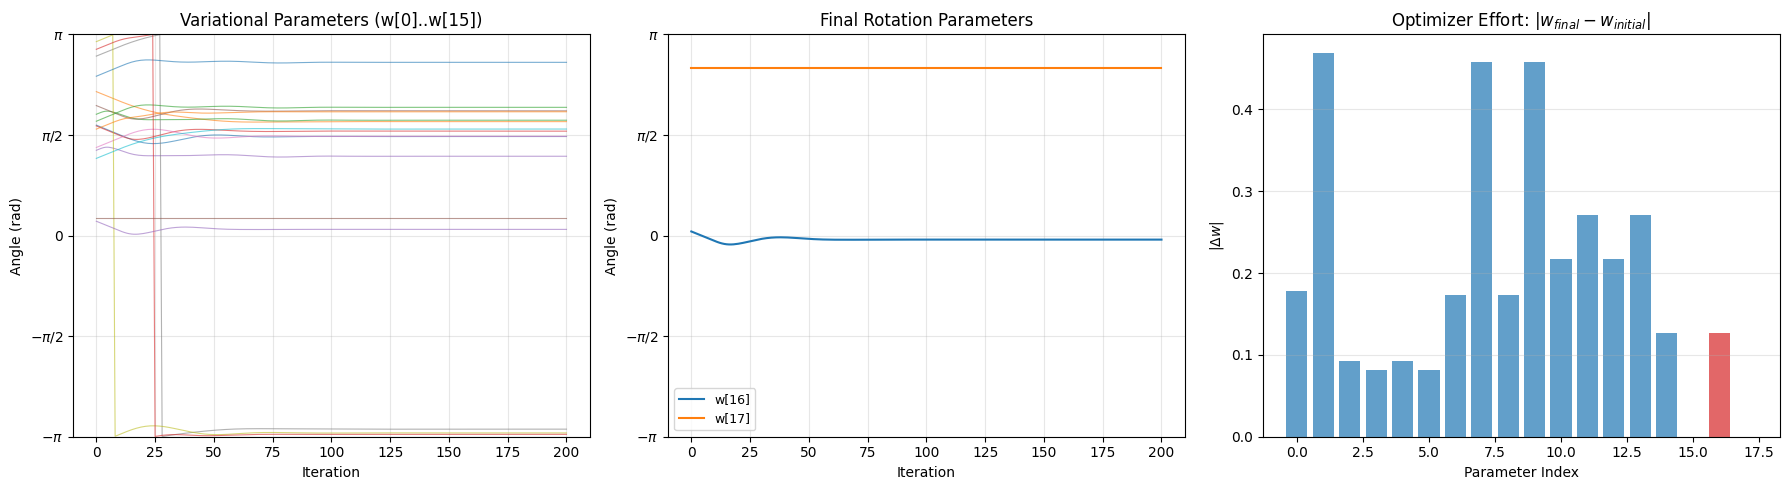

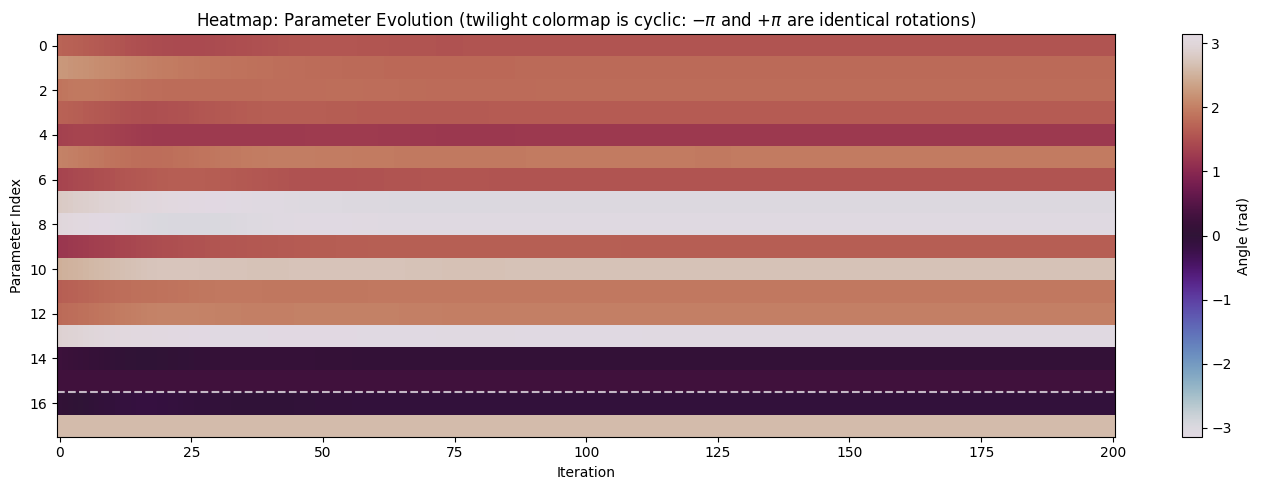

In [17]:
params_array_fad = np.array(history_fixed_ad['params'])
params_wrapped_fad = np.mod(params_array_fad + np.pi, 2 * np.pi) - np.pi

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ax = axes[0]
for k in range(nparams_fixed - 2):
    ax.plot(params_wrapped_fad[:, k], alpha=0.6, linewidth=0.8)
ax.set_title(f'Variational Parameters (w[0]..w[{nparams_fixed-3}])')
ax.set_xlabel('Iteration'); ax.set_ylabel('Angle (rad)')
ax.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
ax.set_yticklabels(['$-\\pi$', '$-\\pi/2$', '0', '$\\pi/2$', '$\\pi$']); ax.set_ylim([-np.pi, np.pi])
ax.grid(True, alpha=0.3)

ax = axes[1]
for k in range(nparams_fixed-2, nparams_fixed):
    ax.plot(params_wrapped_fad[:, k], label=f'w[{k}]', linewidth=1.5)
ax.set_title('Final Rotation Parameters')
ax.set_xlabel('Iteration'); ax.set_ylabel('Angle (rad)')
ax.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
ax.set_yticklabels(['$-\\pi$', '$-\\pi/2$', '0', '$\\pi/2$', '$\\pi$']); ax.set_ylim([-np.pi, np.pi])
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[2]
delta = np.abs(params_array_fad[-1] - params_array_fad[0])
colors = ['tab:blue']*(nparams_fixed-2) + ['tab:red']*2
ax.bar(range(nparams_fixed), delta, color=colors, alpha=0.7)
ax.set_title('Optimizer Effort: $|w_{final} - w_{initial}|$')
ax.set_xlabel('Parameter Index'); ax.set_ylabel('$|\\Delta w|$'); ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout(); plt.show()

# --- Heatmap ---
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(params_wrapped_fad.T, aspect='auto', cmap='twilight', interpolation='nearest', vmin=-np.pi, vmax=np.pi)
ax.set_xlabel('Iteration'); ax.set_ylabel('Parameter Index')
ax.set_title('Heatmap: Parameter Evolution (twilight colormap is cyclic: $-\\pi$ and $+\\pi$ are identical rotations)')
plt.colorbar(im, ax=ax, label='Angle (rad)')
ax.axhline(y=nparams_fixed-2.5, color='white', linewidth=1.5, linestyle='--', alpha=0.7)
plt.tight_layout(); plt.show()

---
## 14. Decision Boundary Evolution During Training

Shows how the decision boundary evolves over training. The background color encodes the model prediction $\langle Z \rangle$: blue = class +1, red = class $-1$. Dashed black contour marks $\langle Z \rangle = 0$ (decision boundary). Data points are colored by the model prediction at each snapshot.

[Qibo 0.2.23|INFO|2026-05-26 10:31:41]: Using numpy backend on /CPU:0


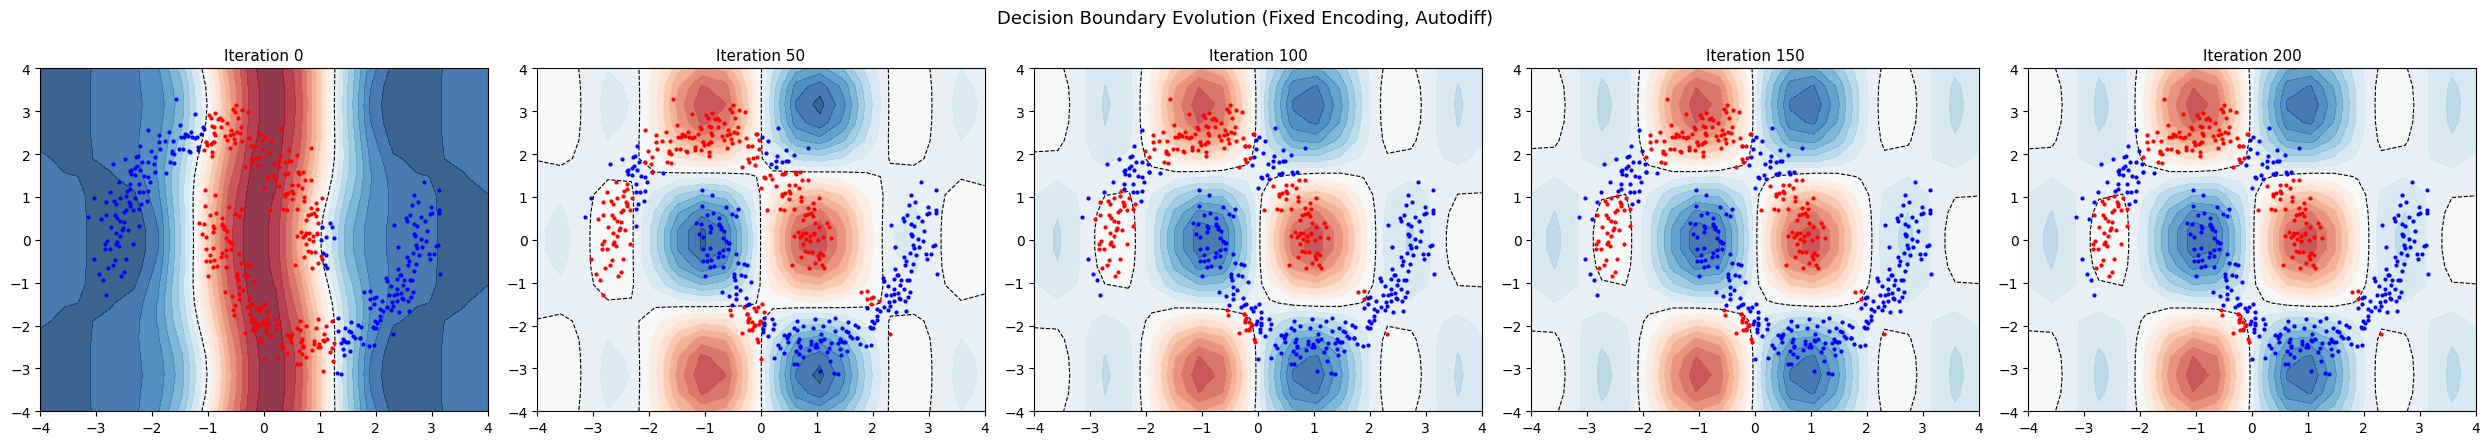

In [18]:
qibo.set_backend("numpy")  # fast numpy path, mathematically identical to qibo+torch

snapshot_iters = sorted(set([0, n_iter // 4, n_iter // 2, 3 * n_iter // 4, n_iter]))
xx, yy = np.meshgrid(np.linspace(-4, 4, 20), np.linspace(-4, 4, 20))
X_grid = np.stack([xx.flatten(), yy.flatten()], axis=1)
cm = plt.cm.RdBu

fig, axes = plt.subplots(1, len(snapshot_iters), figsize=(5 * len(snapshot_iters), 4.5))
for idx, it_idx in enumerate(snapshot_iters):
    ax = axes[idx]
    snap_params = params_array_fad[it_idx]
    # Batched forward over the whole grid + the whole training cloud.
    Z1 = fast_predict(snap_params, X_grid, circuit_type='fixed').reshape(xx.shape)
    preds_pad = fast_predict(snap_params, np.asarray(X_pad), circuit_type='fixed')

    ax.contourf(xx, yy, Z1, levels=np.arange(-1, 1, 0.1), cmap=cm, alpha=0.8, extend="both")
    ax.contour(xx, yy, Z1, levels=[0.0], colors="black", linestyles="--", linewidths=0.8)
    for xp, pred in zip(X_pad, preds_pad):
        ax.plot(xp[0], xp[1], 'o', color='blue' if pred > 0 else 'red', markersize=2)
    ax.set_title(f'Iteration {it_idx}', fontsize=11)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)

plt.suptitle('Decision Boundary Evolution (Fixed Encoding, Autodiff)', fontsize=13)
plt.tight_layout(); plt.show()

---
## 15. Final Decision Boundary (Autodiff, Fixed Encoding)

Each data point is colored according to the **model's prediction** (not the true label).

[Qibo 0.2.23|INFO|2026-05-26 10:31:42]: Using numpy backend on /CPU:0


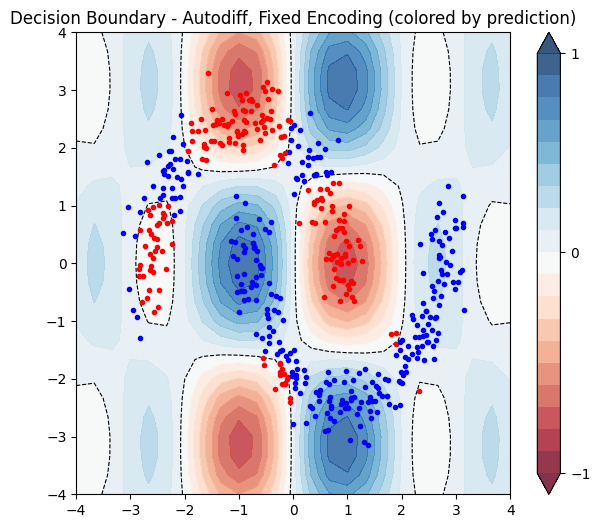

In [19]:
qibo.set_backend("numpy")  # fast numpy path

plt.figure(figsize=(7, 6))
xx, yy = np.meshgrid(np.linspace(-4, 4, 25), np.linspace(-4, 4, 25))
X_grid = np.stack([xx.flatten(), yy.flatten()], axis=1)

# Final autodiff parameters live in `params_np_fixed_ad`.
Z1 = fast_predict(params_np_fixed_ad, X_grid, circuit_type='fixed').reshape(xx.shape)
preds_pad = fast_predict(params_np_fixed_ad, np.asarray(X_pad), circuit_type='fixed')

cm = plt.cm.RdBu
cnt = plt.contourf(xx, yy, Z1, levels=np.arange(-1, 1, 0.1), cmap=cm, alpha=0.8, extend="both")
plt.contour(xx, yy, Z1, levels=[0.0], colors="black", linestyles="--", linewidths=0.8)
plt.colorbar(cnt, ticks=[-1, 0, 1])
for xp, pred in zip(X_pad, preds_pad):
    plt.plot(xp[0], xp[1], 'o', color='blue' if pred > 0 else 'red', markersize=3)
plt.title('Decision Boundary - Autodiff, Fixed Encoding (colored by prediction)')
plt.show()

---
## 16. Interactive Bloch Sphere — Fixed Encoding (2 qubits)

Use the slider below to scrub through every training iteration.

**Top row — 3D Bloch sphere**: each point is a data sample's qubit state after the circuit. Stem lines drop to the equatorial plane ($z = 0$) to help judge depth.

**Bottom row — 2D front projection (XZ plane)**: the same points projected onto the plane you see when looking at the sphere from the front. The vertical axis is $Z \approx \langle Z \rangle$ (the prediction). Points above the dashed line are predicted as class +1, below as class $-1$.

- **Qubit 0** (measured): its $z$-coordinate directly determines the classifier output. Training should push blue circles toward $|0\rangle$ (top) and red triangles toward $|1\rangle$ (bottom).
- **Qubit 1** (ancilla): entangled with qubit 0 via CZ gates, its role is to assist the computation.


In [20]:
qibo.set_backend("numpy")  # Bloch path bypasses qibo

# Pre-compute Bloch coordinates for every (iteration, sample). One batched
# numpy forward per iteration -- cheap.
print("Pre-computing Bloch sphere states (this populates the slider frames)...")
bloch_fixed_ad = precompute_bloch(history_fixed_ad['params'], X_bloch, nqubits, circuit_type='fixed')

# Self-contained Plotly viewer. All frame data is embedded in the figure JSON,
# so once this cell has been run the slider keeps working in the saved
# notebook (no kernel needed).
fig_bloch_fixed_ad = make_bloch_plotly(bloch_fixed_ad, Y_bloch, 2,
                                  suptitle="Bloch Sphere — Fixed Encoding VQC (slider scrubs training iteration)", height=740)
fig_bloch_fixed_ad.show()


[Qibo 0.2.23|INFO|2026-05-26 10:31:42]: Using numpy backend on /CPU:0


Pre-computing Bloch sphere states (this populates the slider frames)...
  Computing iteration 0/200...
  Computing iteration 50/200...
  Computing iteration 100/200...
  Computing iteration 150/200...
  Computing iteration 200/200...
  Done.


---
## 16b. Post-encoding Bloch sphere — Fixed Encoding (input to the variational block)

Up to here we have only looked at the Bloch sphere at the **end** of the circuit. But the user-facing question is sharper:

> Is the ansatz really doing anything, or is the feature encoding alone already separating the classes?

To answer that, we visualise the qubit state **immediately after the encoding block**, before any variational layer touches it. For the fixed encoding ($\theta = x_j$, no trainable parameters) this state depends only on the data, so it is **the same throughout training** — a single static plot is enough.

If you already see two well-separated clusters here, the ansatz only has to perform a small final rotation; the encoding is doing most of the classification work. If the clusters are mixed, the ansatz is genuinely entangling and rotating things to disentangle the moons.



[Qibo 0.2.23|INFO|2026-05-26 10:31:44]: Using numpy backend on /CPU:0


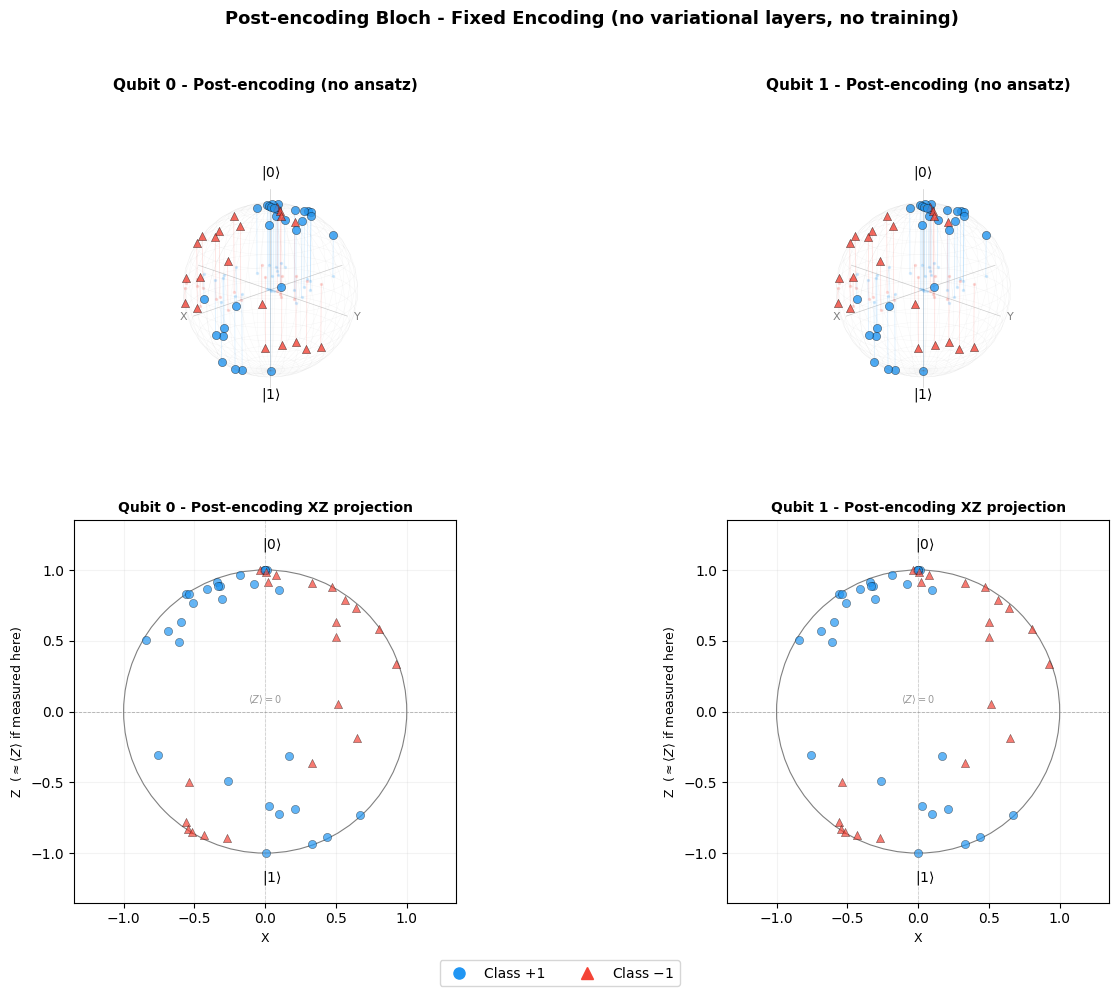

In [21]:
qibo.set_backend("numpy")  # PS/Bloch path bypasses qibo

# Encoding-only state for every Bloch sample, in a single batched call.
states_fixed_enc = fast_states(np.zeros(1), X_bloch, circuit_type='fixed_encoding')  # (n_bloch_samples, 4)
bloch_fixed_enc = {f'q{q}': state_to_bloch_batch(states_fixed_enc, qubit=q) for q in range(nqubits)}

fig = plt.figure(figsize=(14, 10))
for q_idx in range(2):
    ax3d = fig.add_subplot(2, 2, q_idx + 1, projection='3d')
    draw_bloch_sphere(ax3d, title=f'Qubit {q_idx} - Post-encoding (no ansatz)')
    bdata = bloch_fixed_enc[f'q{q_idx}']
    for i in range(n_bloch_samples):
        color = '#2196F3' if Y_bloch[i] > 0 else '#F44336'
        marker = 'o' if Y_bloch[i] > 0 else '^'
        bx, by, bz = bdata[i]
        ax3d.scatter(bx, by, bz, c=color, marker=marker, s=35, alpha=0.8,
                   edgecolors='k', linewidths=0.3, zorder=5)
        ax3d.plot([bx, bx], [by, by], [bz, 0], color=color, alpha=0.15, linewidth=0.6)
        ax3d.scatter(bx, by, 0, c=color, marker='.', s=8, alpha=0.15)
    ax3d.view_init(elev=20, azim=45)

    ax2d = fig.add_subplot(2, 2, q_idx + 3)
    circle = plt.Circle((0, 0), 1, fill=False, color='gray', linewidth=0.8)
    ax2d.add_patch(circle)
    ax2d.axhline(y=0, color='gray', linestyle='--', linewidth=0.6, alpha=0.6)
    ax2d.axvline(x=0, color='gray', linestyle='--', linewidth=0.6, alpha=0.3)
    ax2d.text(0.05, 1.15, r'$|0\rangle$', fontsize=10, ha='center', fontweight='bold')
    ax2d.text(0.05, -1.2, r'$|1\rangle$', fontsize=10, ha='center', fontweight='bold')
    ax2d.text(0, 0.06, r'$\langle Z \rangle = 0$', fontsize=7, ha='center', color='gray', alpha=0.8)
    for i in range(n_bloch_samples):
        color = '#2196F3' if Y_bloch[i] > 0 else '#F44336'
        marker = 'o' if Y_bloch[i] > 0 else '^'
        ax2d.scatter(bdata[i, 0], bdata[i, 2], c=color, marker=marker, s=35,
                   alpha=0.7, edgecolors='k', linewidths=0.3)
    ax2d.set_xlim(-1.35, 1.35); ax2d.set_ylim(-1.35, 1.35)
    ax2d.set_xlabel('X', fontsize=9)
    ax2d.set_ylabel(r'Z  ($\approx \langle Z \rangle$ if measured here)', fontsize=9)
    ax2d.set_title(f'Qubit {q_idx} - Post-encoding XZ projection', fontsize=10, fontweight='bold')
    ax2d.set_aspect('equal'); ax2d.grid(True, alpha=0.15)

fig.legend([plt.Line2D([0],[0], marker='o', color='#2196F3', linestyle='', markersize=8),
            plt.Line2D([0],[0], marker='^', color='#F44336', linestyle='', markersize=8)],
           ['Class +1', 'Class $-$1'], loc='lower center', ncol=2, fontsize=10)
plt.suptitle('Post-encoding Bloch - Fixed Encoding (no variational layers, no training)',
            fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.savefig('figures/case1-bloch-fixed.png', dpi=150, bbox_inches='tight'); plt.show()


---
## 17. VQC Fixed Encoding — Parameter-Shift Rule

We re-train the **same architecture** using the parameter-shift rule. We switch to the NumPy backend and use the same Adam hyperparameters with the same initial parameters.

### Computational cost

For 18 parameters and $N_{\text{train}}$ training points, each iteration requires $2 \times 18 \times N_{\text{train}}$ circuit evaluations for the gradient alone, plus $N_{\text{train}}$ for the forward pass and $N_{\text{val}}$ for validation.

In [22]:
# Save autodiff results
history_fixed_autodiff = history_fixed_ad.copy()
params_fixed_autodiff_final = params_np_fixed_ad.copy()

# Re-initialize identically
np.random.seed(0)
params_fixed_ps = np.pi * np.random.rand(nparams_fixed).copy()

[Qibo 0.2.23|INFO|2026-05-26 10:31:45]: Using numpy backend on /CPU:0


SEED=0 RUN  (matches AD seed=0 init for the methodology comparison)

Seed=0 PS:  final val_acc=0.8267  best val_acc=0.8000 (at iter 81/199)
Time: 0.12 min  |  Evals: 2,605,000

MULTI-SEED EXPLORATION
Multi-seed PS training [Fixed VQC]: 8 seeds x 200 iter (fixed)
  seed=0: final val_loss=0.6477 val_acc=0.8267  best (val_acc)=0.8800 (it  65)  time=6.8s
  seed=1: final val_loss=0.6477 val_acc=0.8267  best (val_acc)=0.8667 (it  79)  time=6.6s
  seed=2: final val_loss=0.6477 val_acc=0.8267  best (val_acc)=0.8800 (it  64)  time=6.7s
  seed=3: final val_loss=0.6477 val_acc=0.8267  best (val_acc)=0.8800 (it  50)  time=6.7s
  seed=4: final val_loss=0.6477 val_acc=0.8267  best (val_acc)=0.8667 (it  42)  time=6.6s
  seed=5: final val_loss=0.6477 val_acc=0.8267  best (val_acc)=0.8533 (it  46)  time=6.6s
  seed=6: final val_loss=0.6477 val_acc=0.8267  best (val_acc)=0.8667 (it  77)  time=6.6s
  seed=7: final val_loss=0.6477 val_acc=0.8267  best (val_acc)=0.8667 (it  71)  time=6.6s
-> Best: seed=3  

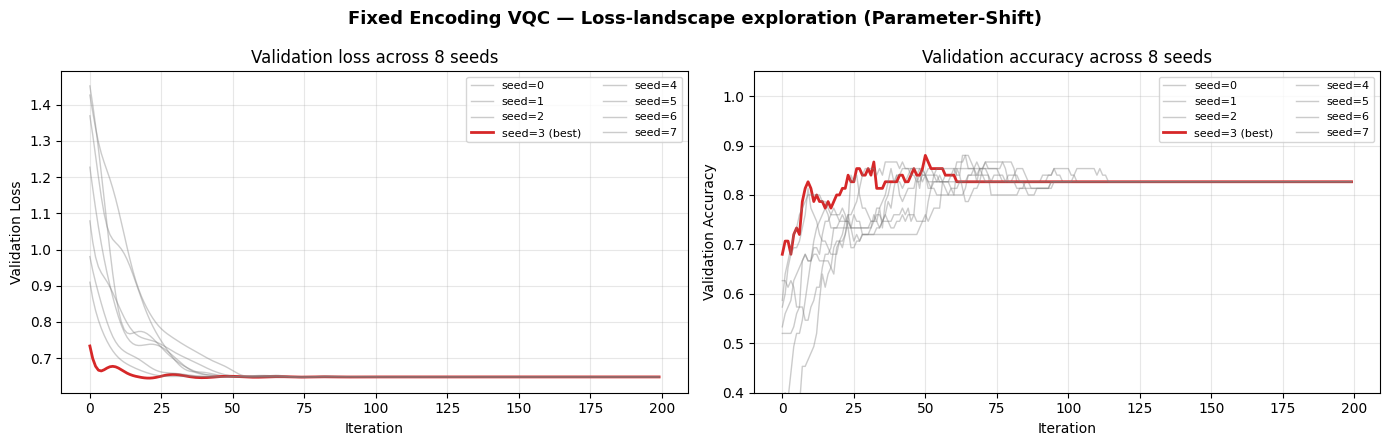


Final val_acc across seeds: min=0.8267  mean=0.8267  max=0.8267
Best  val_acc across seeds: min=0.8533  mean=0.8700  max=0.8800


In [23]:
qibo.set_backend("numpy")  # PS path bypasses qibo
n_iter_ps = 200
lr_ps = 0.015

# === 1) seed=0 run for the AD-vs-PS methodology comparison =============
print("=" * 70)
print("SEED=0 RUN  (matches AD seed=0 init for the methodology comparison)")
print("=" * 70)
np.random.seed(0)
params_init_seed0 = np.pi * np.random.rand(nparams_fixed).copy()
reset_counter(); t0 = time()
history_fixed_ps_seed0 = train_ps_run(params_init_seed0, X_train, Y_train, X_val, Y_val,
    circuit_type='fixed', n_iter=n_iter_ps, lr=lr_ps, store_param_history=True)
ps_time = (time() - t0) / 60.0
ps_evals = get_counter()
print(f"\nSeed=0 PS:  final val_acc={history_fixed_ps_seed0['val_acc'][-1]:.4f}  "
      f"best val_acc={history_fixed_ps_seed0['best_val_acc']:.4f} "
      f"(at iter {history_fixed_ps_seed0['best_val_iter']}/{n_iter_ps - 1})")
print(f"Time: {ps_time:.2f} min  |  Evals: {ps_evals:,}")

# === 2) Multi-seed exploration to escape local minima ==================
print("\n" + "=" * 70)
print("MULTI-SEED EXPLORATION")
print("=" * 70)
n_seeds_fixed = 8
best_run_fixed, all_runs_fixed = train_ps_multi_seed(list(range(n_seeds_fixed)), nparams_fixed, X_train, Y_train, X_val, Y_val,
    circuit_type='fixed', n_iter=n_iter_ps, lr=lr_ps, label='Fixed VQC', select_by='val_acc')

# Use the best run (best-val checkpoint) downstream
history_fixed_ps = best_run_fixed
params_fixed_ps = best_run_fixed['best_val_params']

print("\n-- Final cost (test, best multi-seed PS, best-val checkpoint) --")
Cost_function_np(params_fixed_ps, X_test, Y_test, nqubits, circuit_type='fixed')
total_evals_multi_fixed = sum(r['evals'] for r in all_runs_fixed)
total_time_multi_fixed  = sum(r['time_s'] for r in all_runs_fixed) / 60.0
print(f"\nTotal multi-seed budget: {total_evals_multi_fixed:,} evals  |  "
      f"{total_time_multi_fixed:.2f} min")

# === 3) Loss-landscape visualisation ==================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for r in all_runs_fixed:
    is_best = (r is best_run_fixed)
    color = 'tab:red' if is_best else 'tab:gray'
    alpha = 1.0 if is_best else 0.4
    lw = 2.0 if is_best else 1.0
    label_ = f'seed={r["seed"]} (best)' if is_best else f'seed={r["seed"]}'
    axes[0].plot(r['val_loss'], color=color, alpha=alpha, linewidth=lw, label=label_)
    axes[1].plot(r['val_acc'],  color=color, alpha=alpha, linewidth=lw, label=label_)
axes[0].set_xlabel('Iteration'); axes[0].set_ylabel('Validation Loss')
axes[0].set_title(f'Validation loss across {n_seeds_fixed} seeds')
axes[0].grid(True, alpha=0.3); axes[0].legend(fontsize=8, ncol=2)
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('Validation Accuracy')
axes[1].set_title(f'Validation accuracy across {n_seeds_fixed} seeds')
axes[1].set_ylim([0.4, 1.05]); axes[1].grid(True, alpha=0.3); axes[1].legend(fontsize=8, ncol=2)
plt.suptitle('Fixed Encoding VQC — Loss-landscape exploration (Parameter-Shift)',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('figures/case1-ps-fixed-curves.png', dpi=150, bbox_inches='tight'); plt.show()

final_accs = [r['val_acc'][-1]   for r in all_runs_fixed]
best_accs  = [r['best_val_acc']  for r in all_runs_fixed]
print(f"\nFinal val_acc across seeds: min={min(final_accs):.4f}  "
      f"mean={np.mean(final_accs):.4f}  max={max(final_accs):.4f}")
print(f"Best  val_acc across seeds: min={min(best_accs):.4f}  "
      f"mean={np.mean(best_accs):.4f}  max={max(best_accs):.4f}")


---
## 18. Final Decision Boundary (Parameter-Shift, Fixed Encoding)

[Qibo 0.2.23|INFO|2026-05-26 10:32:46]: Using numpy backend on /CPU:0


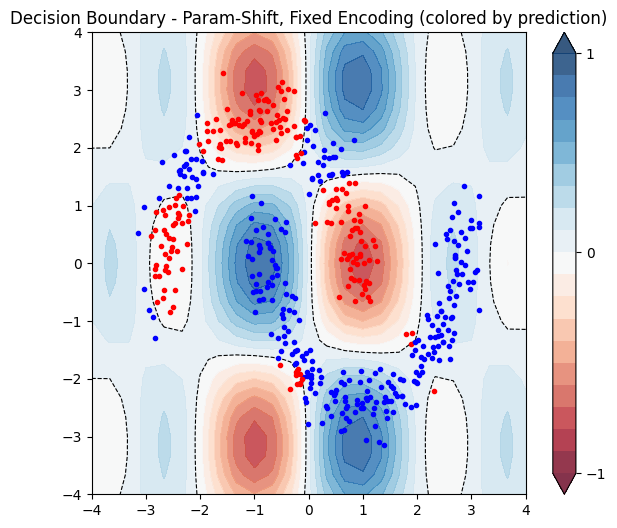

In [24]:
qibo.set_backend("numpy")  # PS/Bloch path bypasses qibo

plt.figure(figsize=(7, 6))
xx, yy = np.meshgrid(np.linspace(-4, 4, 25), np.linspace(-4, 4, 25))
X_grid = np.stack([xx.flatten(), yy.flatten()], axis=1)
preds_grid = fast_predict(params_fixed_ps, X_grid, circuit_type='fixed')
Z1 = preds_grid.reshape(xx.shape)
cm = plt.cm.RdBu
cnt = plt.contourf(xx, yy, Z1, levels=np.arange(-1, 1, 0.1), cmap=cm, alpha=0.8, extend="both")
plt.contour(xx, yy, Z1, levels=[0.0], colors="black", linestyles="--", linewidths=0.8)
plt.colorbar(cnt, ticks=[-1, 0, 1])
preds_pad = fast_predict(params_fixed_ps, np.asarray(X_pad), circuit_type='fixed')
for xp, pred in zip(X_pad, preds_pad):
    plt.plot(xp[0], xp[1], 'o', color='blue' if pred > 0 else 'red', markersize=3)
plt.title('Decision Boundary - Param-Shift, Fixed Encoding (colored by prediction)'); plt.show()


---
## 19. Comparison: Autodiff vs Parameter-Shift (Fixed Encoding)

Both methods start from the **same initial parameters** with identical Adam hyperparameters. Since both compute **exact analytical gradients** (no noise, no approximation), the training curves **should be identical**. Any differences would indicate a bug.

The bottom row shows the difference: values near zero confirm correct implementation.

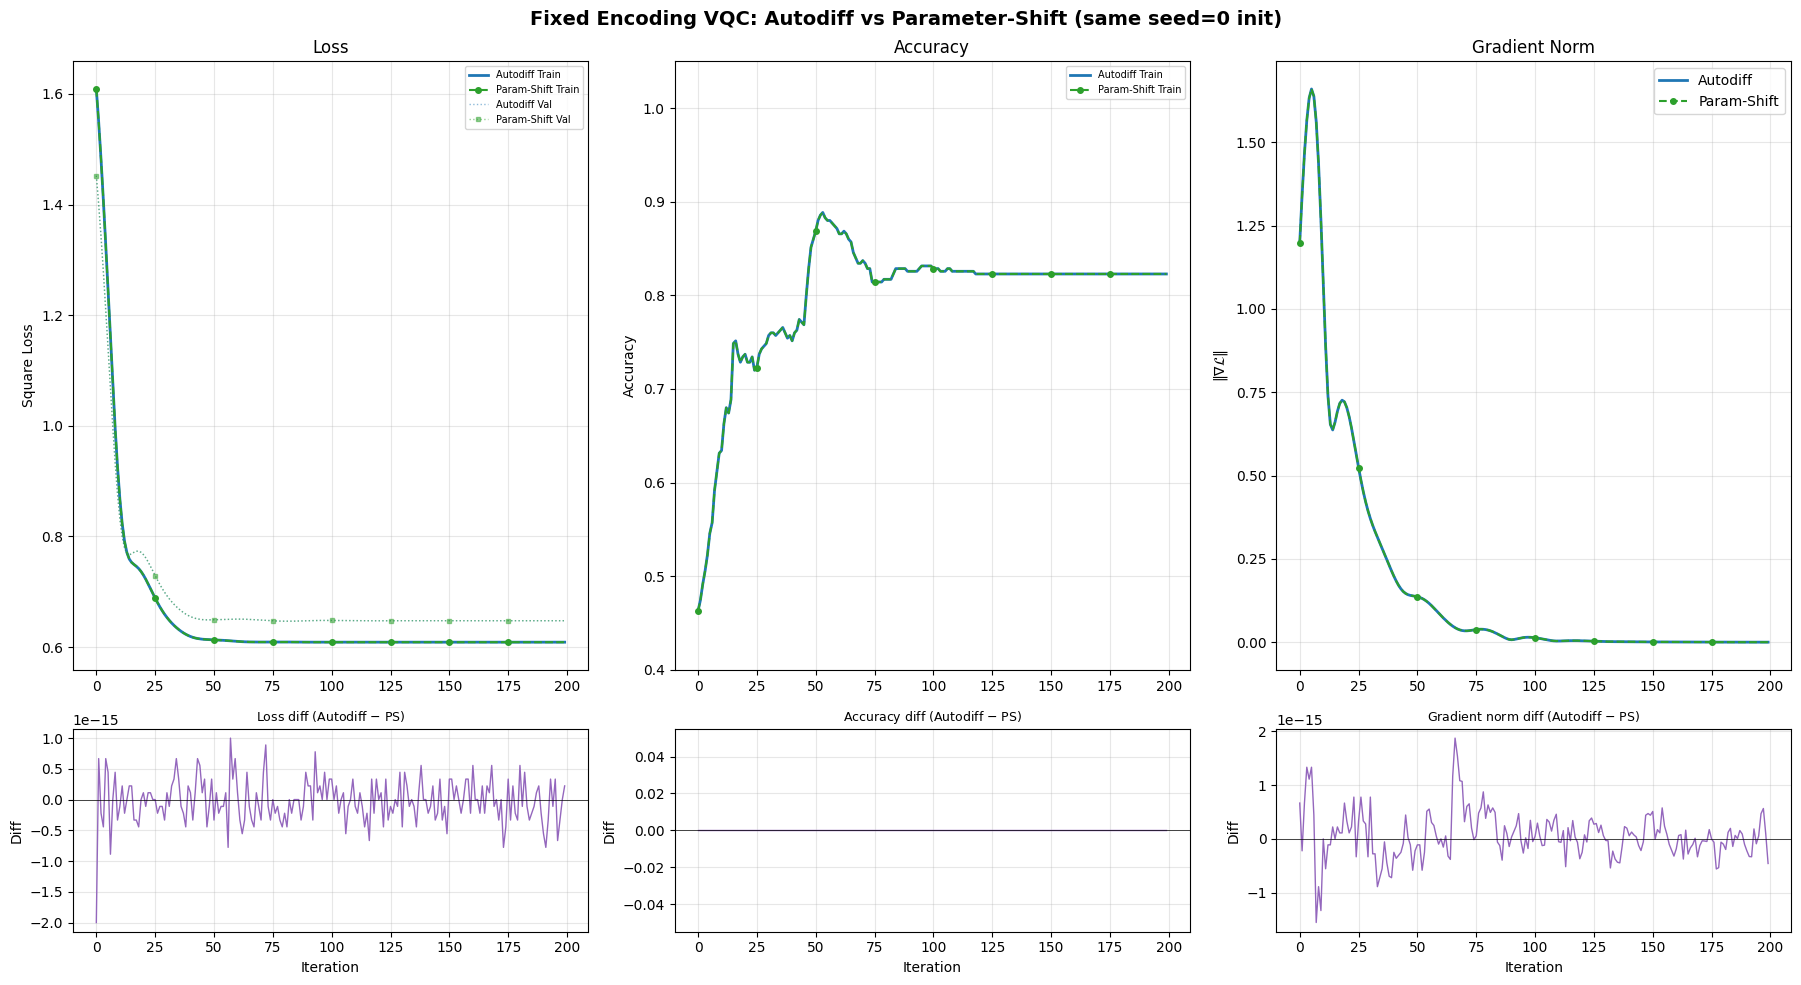

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), gridspec_kw={'height_ratios': [3, 1]})
mk_every = max(1, n_iter // 8)

axes[0,0].plot(history_fixed_autodiff['train_loss'], label='Autodiff Train', color='tab:blue', linewidth=2)
axes[0,0].plot(history_fixed_ps_seed0['train_loss'], label='Param-Shift Train', color='tab:green', linewidth=1.5, linestyle='--', marker='o', markevery=mk_every, markersize=4)
axes[0,0].plot(history_fixed_autodiff['val_loss'], label='Autodiff Val', color='tab:blue', linewidth=1, alpha=0.5, linestyle=':')
axes[0,0].plot(history_fixed_ps_seed0['val_loss'], label='Param-Shift Val', color='tab:green', linewidth=1, alpha=0.5, linestyle=':', marker='s', markevery=mk_every, markersize=3)
axes[0,0].set_ylabel('Square Loss'); axes[0,0].set_title('Loss'); axes[0,0].legend(fontsize=7); axes[0,0].grid(True, alpha=0.3)

axes[0,1].plot(history_fixed_autodiff['train_acc'], label='Autodiff Train', color='tab:blue', linewidth=2)
axes[0,1].plot(history_fixed_ps_seed0['train_acc'], label='Param-Shift Train', color='tab:green', linewidth=1.5, linestyle='--', marker='o', markevery=mk_every, markersize=4)
axes[0,1].set_ylabel('Accuracy'); axes[0,1].set_title('Accuracy'); axes[0,1].legend(fontsize=7)
axes[0,1].grid(True, alpha=0.3); axes[0,1].set_ylim([0.4, 1.05])

axes[0,2].plot(history_fixed_autodiff['grad_norms'], label='Autodiff', color='tab:blue', linewidth=2)
axes[0,2].plot(history_fixed_ps_seed0['grad_norms'], label='Param-Shift', color='tab:green', linewidth=1.5, linestyle='--', marker='o', markevery=mk_every, markersize=4)
axes[0,2].set_ylabel('$\\|\\nabla \\mathcal{L}\\|$'); axes[0,2].set_title('Gradient Norm'); axes[0,2].legend(); axes[0,2].grid(True, alpha=0.3)

for col, (ad, ps, title) in enumerate([
    (history_fixed_autodiff['train_loss'], history_fixed_ps_seed0['train_loss'], 'Loss diff'),
    (history_fixed_autodiff['train_acc'], history_fixed_ps_seed0['train_acc'], 'Accuracy diff'),
    (history_fixed_autodiff['grad_norms'], history_fixed_ps_seed0['grad_norms'], 'Gradient norm diff')]):
    diff = np.array(ad) - np.array(ps)
    axes[1,col].plot(diff, color='tab:purple', linewidth=1)
    axes[1,col].axhline(y=0, color='black', linewidth=0.5)
    axes[1,col].set_xlabel('Iteration'); axes[1,col].set_ylabel('Diff')
    axes[1,col].set_title(f'{title} (Autodiff $-$ PS)', fontsize=9); axes[1,col].grid(True, alpha=0.3)

plt.suptitle('Fixed Encoding VQC: Autodiff vs Parameter-Shift (same seed=0 init)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('figures/case1-ad-vs-ps-fixed.png', dpi=150, bbox_inches='tight'); plt.show()

In [26]:
print('=' * 70)
print('FAIR COMPARISON: Autodiff vs Parameter-Shift (Fixed Encoding)')
print('=' * 70)
print(f'{"Metric":<35} {"Autodiff":>15} {"Param-Shift":>17}')
print('-' * 70)
print(f'{"Total circuit evaluations":<35} {autodiff_evals:>15,} {ps_evals:>17,}')
print(f'{"Eval ratio (PS / AD), measured":<35} {"":>15} {ps_evals/autodiff_evals:>16.1f}x')

# Theoretical ratio per iteration:
#   AD: forward over train + forward over val           = N_train + N_val
#   PS: same forward + 2*nparams gradient forwards      = N_train * (1 + 2*nparams) + N_val
# (Validation overhead does NOT scale with nparams, so the "pure" 2*nparams
#  idealization is only exact in the N_val << N_train limit.)
N_train_ = len(X_train); N_val_ = len(X_val)
exact_expected = (N_train_ * (1 + 2*nparams_fixed) + N_val_) / (N_train_ + N_val_)
ideal_expected = 2 * nparams_fixed
print(f'{"Theoretical ratio (exact formula)":<35} {"":>15} {exact_expected:>16.1f}x')
print(f'{"Theoretical ratio (2*Nparams, ideal)":<35} {"":>15} {ideal_expected:>16.1f}x')
print(f'{"Wall-clock time (min)":<35} {autodiff_time:>15.2f} {ps_time:>17.2f}')
print(f'{"Backend":<35} {"qibo+pytorch":>15} {"hand-rolled numpy":>17}')
print('-' * 70)
print()
print('AD goes through qibo+pytorch+autograd because we need an autograd graph')
print('for backward(). PS bypasses qibo entirely: a hand-written numpy forward')
print('vectorised over the 350 training samples is dramatically faster than')
print('qibo per-sample dispatch on tiny (2-qubit) circuits, so the wall-clock')
print('numbers above no longer faithfully reflect the *theoretical* PS-vs-AD')
print('cost. The eval-count ratio is the right comparison and still applies on')
print(f'real quantum hardware: PS ~ {2*nparams_fixed}x more circuit runs per gradient,')
print('and the exact per-iteration ratio matches the formula above.')


FAIR COMPARISON: Autodiff vs Parameter-Shift (Fixed Encoding)
Metric                                     Autodiff       Param-Shift
----------------------------------------------------------------------
Total circuit evaluations                    85,075         2,605,000
Eval ratio (PS / AD), measured                                  30.6x
Theoretical ratio (exact formula)                               30.6x
Theoretical ratio (2*Nparams, ideal)                             36.0x
Wall-clock time (min)                         19.70              0.12
Backend                                qibo+pytorch hand-rolled numpy
----------------------------------------------------------------------

AD goes through qibo+pytorch+autograd because we need an autograd graph
for backward(). PS bypasses qibo entirely: a hand-written numpy forward
vectorised over the 350 training samples is dramatically faster than
qibo per-sample dispatch on tiny (2-qubit) circuits, so the wall-clock
numbers above no lon

---
---

# Part 2: VQC with Trainable Encoding (Advanced Technique)

In the standard approach (Part 1), data is injected as $\theta = x_j$. Here we use **trainable encoding weights**: $\theta = w_k \cdot x_j$, where $w_k$ is optimized during training.

This is an **advanced technique** that allows the model to:
- Learn how to **scale** and **weight** different input features.
- Effectively learn a **data-dependent feature map**.
- Increase model expressivity at the cost of 4 additional parameters.

We train with the parameter-shift rule (since Part 1 already proved that autodiff and parameter-shift produce identical results).

### Architecture changes

| | Fixed Encoding (Part 1) | Trainable Encoding (Part 2) |
|---|---|---|
| Encoding formula | $\theta = x_j$ | $\theta = w_k \cdot x_j$ |
| Encoding parameters | 0 | 4 (learnable) |
| Total parameters | 18 | 22 |

[Qibo 0.2.23|INFO|2026-05-26 10:32:47]: Using numpy backend on /CPU:0


Parameters: 22 (trainable encoding) vs 18 (fixed encoding)
Initial encoding weights (all seeds): w_enc = [1, 1, 1, 1]
Variational + final block init: pi * U[0,1] with seed-dependent draw
Multi-seed PS training [Trainable VQC]: 8 seeds x 200 iter (trainable)
  seed=0: final val_loss=0.3671 val_acc=0.9333  best (val_acc)=0.9333 (it 118)  time=8.7s
  seed=1: final val_loss=0.3671 val_acc=0.9333  best (val_acc)=0.9333 (it  93)  time=8.7s
  seed=2: final val_loss=0.4114 val_acc=0.9200  best (val_acc)=0.9200 (it  96)  time=8.7s
  seed=3: final val_loss=0.3671 val_acc=0.9333  best (val_acc)=0.9333 (it 180)  time=8.6s
  seed=4: final val_loss=0.3671 val_acc=0.9333  best (val_acc)=0.9333 (it 113)  time=8.6s
  seed=5: final val_loss=0.3671 val_acc=0.9333  best (val_acc)=0.9333 (it 192)  time=8.5s
  seed=6: final val_loss=0.3671 val_acc=0.9333  best (val_acc)=0.9333 (it 122)  time=8.7s
  seed=7: final val_loss=0.4266 val_acc=0.8800  best (val_acc)=0.9067 (it  82)  time=8.5s
-> Best: seed=6  best_

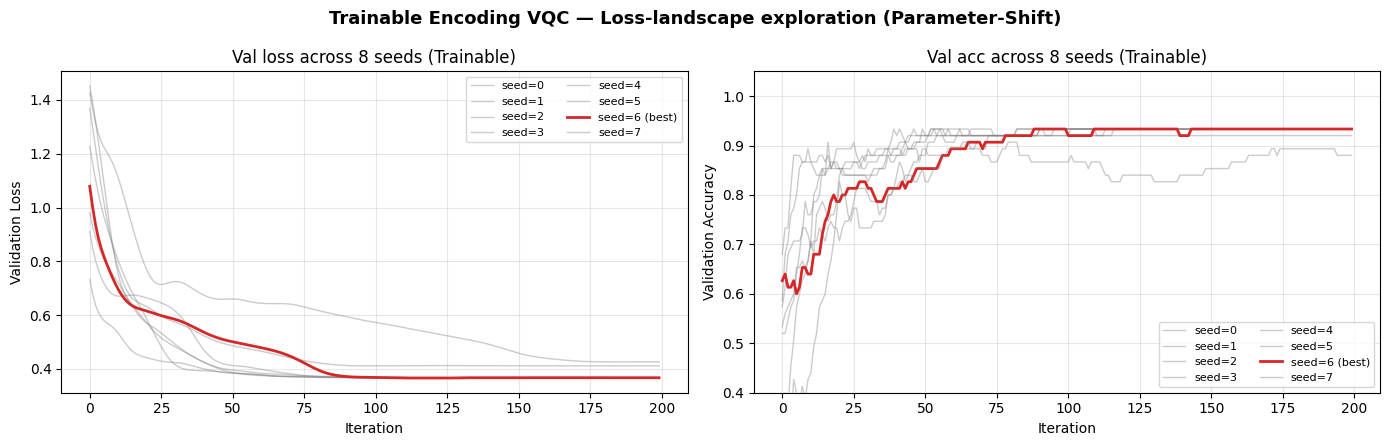

In [27]:
qibo.set_backend("numpy")  # PS path bypasses qibo
nparams_train = 2 * nqubits * nlayers + nqubits + 4  # = 22
print(f'Parameters: {nparams_train} (trainable encoding) vs {nparams_fixed} (fixed encoding)')

# --- Init philosophy ---------------------------------------------------------
# w_enc = [1, 1, 1, 1] for every seed (the "natural" theta = x starting point);
# only the variational + final block varies across seeds. At seed=0 this
# matches exactly the fixed-encoding model's initial circuit state.
def init_trainable(seed, n_params):
    np.random.seed(seed)
    init_var = np.pi * np.random.rand(nparams_fixed)  # 18 values
    params = np.empty(n_params)
    params[:4] = 1.0
    params[4:] = init_var
    return params

print("Initial encoding weights (all seeds): w_enc = [1, 1, 1, 1]")
print("Variational + final block init: pi * U[0,1] with seed-dependent draw")

# Multi-seed exploration
n_seeds_train = 8
best_run_te, all_runs_te = train_ps_multi_seed(list(range(n_seeds_train)), nparams_train, X_train, Y_train, X_val, Y_val,
    circuit_type='trainable', init_fn=init_trainable,
    n_iter=n_iter, lr=lr_ps, label='Trainable VQC', select_by='val_acc', store_param_history=True)

# Use best-by-val params from best seed downstream
history_te = best_run_te
params_trainable = best_run_te['best_val_params']

print("\n-- Final cost (test, best multi-seed) --")
Cost_function_np(params_trainable, X_test, Y_test, nqubits, circuit_type='trainable')
total_evals_te = sum(r['evals'] for r in all_runs_te)
total_time_te  = sum(r['time_s'] for r in all_runs_te) / 60.0
print(f"Total multi-seed budget: {total_evals_te:,} evals  |  {total_time_te:.2f} min")
print(f"\nFinal encoding weights w_enc[0..3]: {params_trainable[:4]}")
print("(initial value: [1.00, 1.00, 1.00, 1.00] — deviations show what the model learned)")

# Loss-landscape plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for r in all_runs_te:
    is_best = (r is best_run_te)
    color = 'tab:red' if is_best else 'tab:gray'
    alpha = 1.0 if is_best else 0.4
    lw = 2.0 if is_best else 1.0
    label_ = f'seed={r["seed"]} (best)' if is_best else f'seed={r["seed"]}'
    axes[0].plot(r['val_loss'], color=color, alpha=alpha, linewidth=lw, label=label_)
    axes[1].plot(r['val_acc'],  color=color, alpha=alpha, linewidth=lw, label=label_)
axes[0].set_xlabel('Iteration'); axes[0].set_ylabel('Validation Loss')
axes[0].set_title(f'Val loss across {n_seeds_train} seeds (Trainable)')
axes[0].grid(True, alpha=0.3); axes[0].legend(fontsize=8, ncol=2)
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('Validation Accuracy')
axes[1].set_title(f'Val acc across {n_seeds_train} seeds (Trainable)')
axes[1].set_ylim([0.4, 1.05]); axes[1].grid(True, alpha=0.3); axes[1].legend(fontsize=8, ncol=2)
plt.suptitle('Trainable Encoding VQC — Loss-landscape exploration (Parameter-Shift)',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('figures/case1-trainable-curves.png', dpi=150, bbox_inches='tight'); plt.show()


---
## 20. Parameter Evolution (Trainable Encoding)

Note the additional **encoding group** (w[0]..w[3]): these multiply the input data. If $w_k > 0$ the model preserves the feature's orientation; $|w_k|$ controls sensitivity to that feature. If $w_k \to 0$, the model ignores the feature.

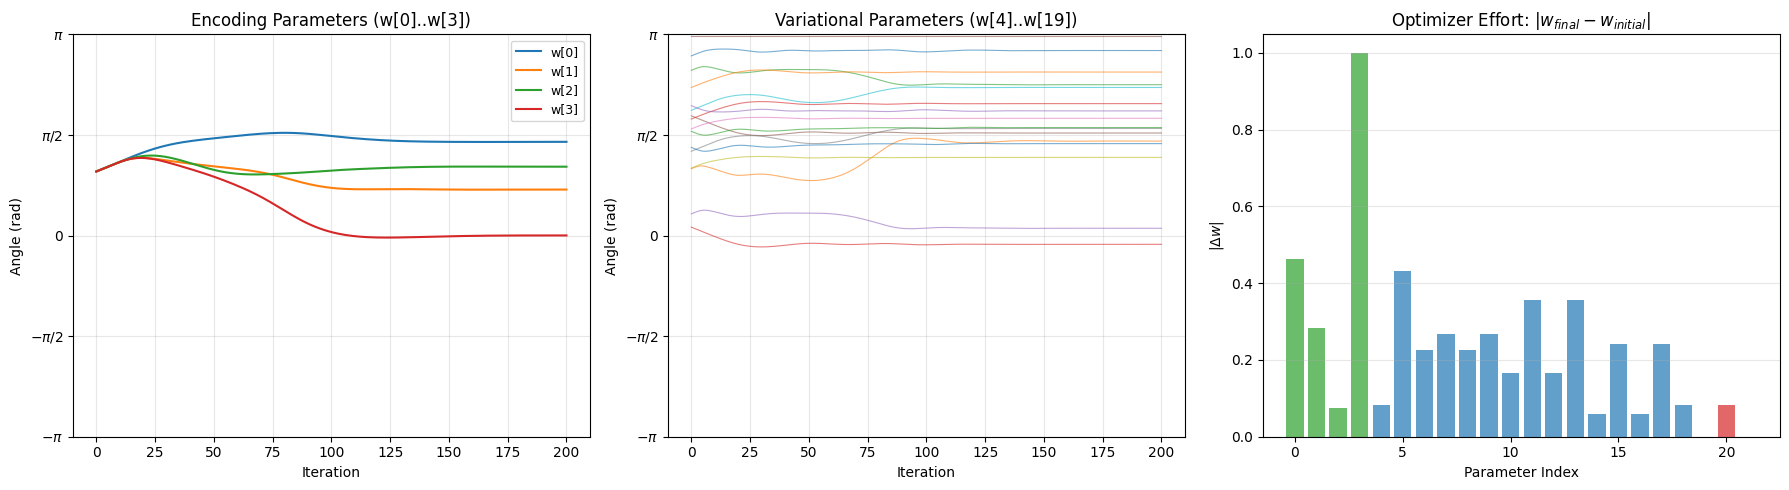

In [28]:
params_array_te = np.array(history_te['params'])
params_wrapped_te = np.mod(params_array_te + np.pi, 2 * np.pi) - np.pi

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ax = axes[0]
for k in range(4):
    ax.plot(params_wrapped_te[:, k], label=f'w[{k}]', linewidth=1.5)
ax.set_title('Encoding Parameters (w[0]..w[3])')
ax.set_xlabel('Iteration'); ax.set_ylabel('Angle (rad)')
ax.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
ax.set_yticklabels(['$-\\pi$', '$-\\pi/2$', '0', '$\\pi/2$', '$\\pi$']); ax.set_ylim([-np.pi, np.pi])
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1]
for k in range(4, nparams_train - 2):
    ax.plot(params_wrapped_te[:, k], alpha=0.6, linewidth=0.8)
ax.set_title(f'Variational Parameters (w[4]..w[{nparams_train-3}])')
ax.set_xlabel('Iteration'); ax.set_ylabel('Angle (rad)')
ax.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
ax.set_yticklabels(['$-\\pi$', '$-\\pi/2$', '0', '$\\pi/2$', '$\\pi$']); ax.set_ylim([-np.pi, np.pi])
ax.grid(True, alpha=0.3)

ax = axes[2]
delta_te = np.abs(params_array_te[-1] - params_array_te[0])
colors_te = ['tab:green']*4 + ['tab:blue']*(nparams_train-6) + ['tab:red']*2
ax.bar(range(nparams_train), delta_te, color=colors_te, alpha=0.7)
ax.set_title('Optimizer Effort: $|w_{final} - w_{initial}|$')
ax.set_xlabel('Parameter Index'); ax.set_ylabel('$|\\Delta w|$'); ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout(); plt.show()

---
## 21. Comparison: Fixed vs Trainable Encoding

Side-by-side training curves and decision boundaries. Both use the same optimizer, learning rate, and number of iterations. The only difference is whether the encoding weights are fixed or trainable.

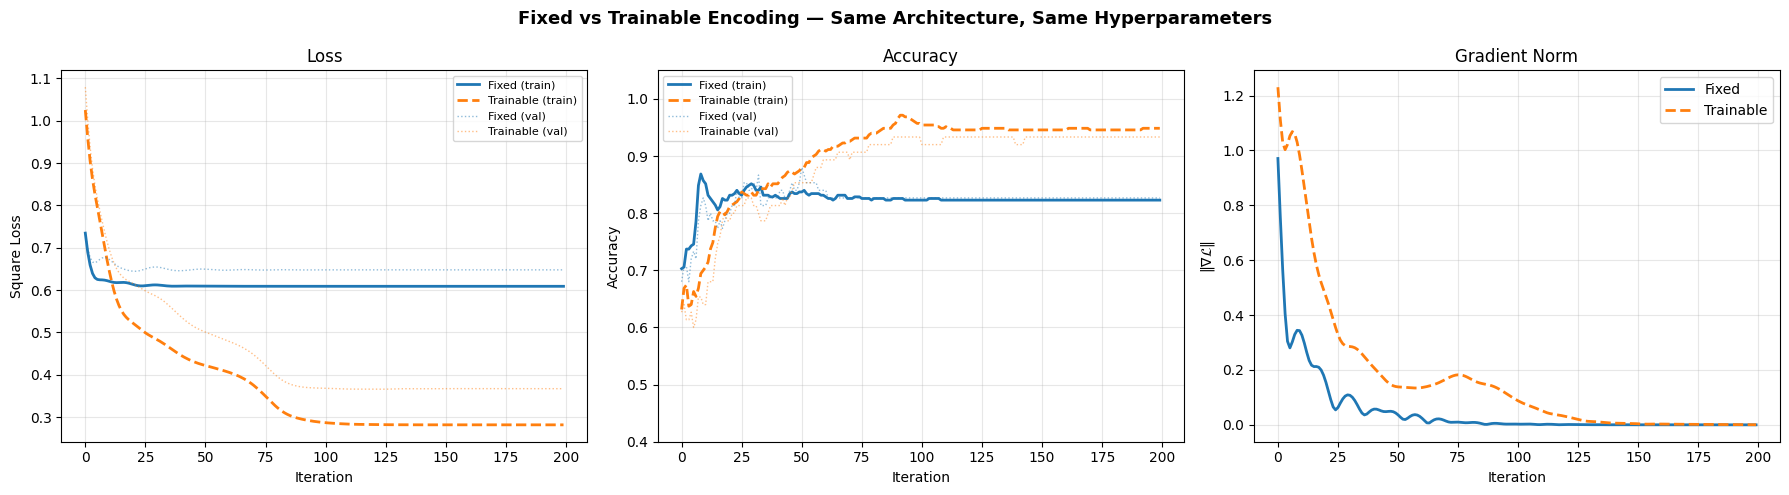

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history_fixed_ps['train_loss'], label='Fixed (train)', color='tab:blue', linewidth=2)
axes[0].plot(history_te['train_loss'], label='Trainable (train)', color='tab:orange', linewidth=2, linestyle='--')
axes[0].plot(history_fixed_ps['val_loss'], label='Fixed (val)', color='tab:blue', linewidth=1, alpha=0.5, linestyle=':')
axes[0].plot(history_te['val_loss'], label='Trainable (val)', color='tab:orange', linewidth=1, alpha=0.5, linestyle=':')
axes[0].set_xlabel('Iteration'); axes[0].set_ylabel('Square Loss')
axes[0].set_title('Loss'); axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].plot(history_fixed_ps['train_acc'], label='Fixed (train)', color='tab:blue', linewidth=2)
axes[1].plot(history_te['train_acc'], label='Trainable (train)', color='tab:orange', linewidth=2, linestyle='--')
axes[1].plot(history_fixed_ps['val_acc'], label='Fixed (val)', color='tab:blue', linewidth=1, alpha=0.5, linestyle=':')
axes[1].plot(history_te['val_acc'], label='Trainable (val)', color='tab:orange', linewidth=1, alpha=0.5, linestyle=':')
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy'); axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3); axes[1].set_ylim([0.4, 1.05])

axes[2].plot(history_fixed_ps['grad_norms'], label='Fixed', color='tab:blue', linewidth=2)
axes[2].plot(history_te['grad_norms'], label='Trainable', color='tab:orange', linewidth=2, linestyle='--')
axes[2].set_xlabel('Iteration'); axes[2].set_ylabel('$\\|\\nabla \\mathcal{L}\\|$')
axes[2].set_title('Gradient Norm'); axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle('Fixed vs Trainable Encoding — Same Architecture, Same Hyperparameters', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

[Qibo 0.2.23|INFO|2026-05-26 10:33:56]: Using numpy backend on /CPU:0


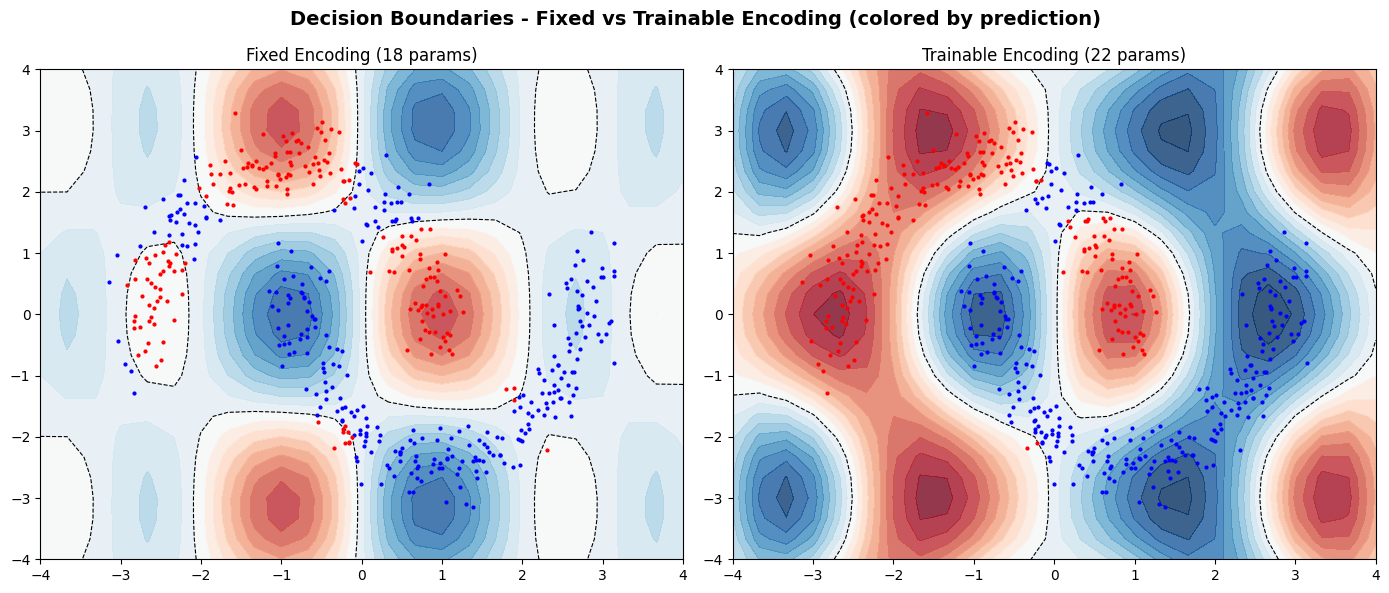


RESULTS: Fixed vs Trainable Encoding
Metric                                Fixed    Trainable
------------------------------------------------------------
Parameters                               18           22
Final Loss (test)                    0.5895       0.2914
Final Acc (test)                     0.8133       0.9333
Final Val Acc                        0.8267       0.9333
------------------------------------------------------------


In [30]:
qibo.set_backend("numpy")  # PS/Bloch path bypasses qibo

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
xx, yy = np.meshgrid(np.linspace(-4, 4, 25), np.linspace(-4, 4, 25))
X_grid = np.stack([xx.flatten(), yy.flatten()], axis=1)
cm = plt.cm.RdBu
X_pad_arr = np.asarray(X_pad)

for ax, params, ct, title in [
    (axes[0], params_fixed_ps, 'fixed', f'Fixed Encoding ({nparams_fixed} params)'),
    (axes[1], params_trainable, 'trainable', f'Trainable Encoding ({nparams_train} params)')]:
    preds = fast_predict(params, X_grid, circuit_type=ct)
    Z_g = preds.reshape(xx.shape)
    ax.contourf(xx, yy, Z_g, levels=np.arange(-1, 1, 0.1), cmap=cm, alpha=0.8, extend="both")
    ax.contour(xx, yy, Z_g, levels=[0.0], colors="black", linestyles="--", linewidths=0.8)
    preds_pad = fast_predict(params, X_pad_arr, circuit_type=ct)
    for xp, pred in zip(X_pad, preds_pad):
        ax.plot(xp[0], xp[1], 'o', color='blue' if pred > 0 else 'red', markersize=2)
    ax.set_title(title, fontsize=12); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)

plt.suptitle('Decision Boundaries - Fixed vs Trainable Encoding (colored by prediction)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

fe_loss, fe_acc = Cost_function_np(params_fixed_ps, X_test, Y_test, nqubits, circuit_type='fixed', verbose=False)
te_loss, te_acc = Cost_function_np(params_trainable, X_test, Y_test, nqubits, circuit_type='trainable', verbose=False)
print('\n' + '='*60)
print('RESULTS: Fixed vs Trainable Encoding')
print('='*60)
print(f'{"Metric":<30} {"Fixed":>12} {"Trainable":>12}')
print('-'*60)
print(f'{"Parameters":<30} {nparams_fixed:>12} {nparams_train:>12}')
print(f'{"Final Loss (test)":<30} {fe_loss:>12.4f} {te_loss:>12.4f}')
print(f'{"Final Acc (test)":<30} {fe_acc:>12.4f} {te_acc:>12.4f}')
print(f'{"Final Val Acc":<30} {history_fixed_ps["val_acc"][-1]:>12.4f} {history_te["val_acc"][-1]:>12.4f}')
print('-'*60)


---
## 22. Interactive Bloch Sphere — Trainable Encoding (2 qubits)

Same layout as Section 16 but with trainable encoding weights. Compare with the fixed encoding Bloch sphere: does training the encoding produce tighter class clusters?


In [31]:
qibo.set_backend("numpy")  # Bloch path bypasses qibo

# Pre-compute Bloch coordinates for every (iteration, sample). One batched
# numpy forward per iteration -- cheap.
print("Pre-computing Bloch sphere states (this populates the slider frames)...")
bloch_te = precompute_bloch(history_te['params'], X_bloch, nqubits, circuit_type='trainable')

# Self-contained Plotly viewer. All frame data is embedded in the figure JSON,
# so once this cell has been run the slider keeps working in the saved
# notebook (no kernel needed).
fig_bloch_te = make_bloch_plotly(bloch_te, Y_bloch, 2,
                                  suptitle="Bloch Sphere — Trainable Encoding VQC (slider scrubs training iteration)", height=740)
fig_bloch_te.show()


[Qibo 0.2.23|INFO|2026-05-26 10:33:57]: Using numpy backend on /CPU:0


Pre-computing Bloch sphere states (this populates the slider frames)...
  Computing iteration 0/200...
  Computing iteration 50/200...
  Computing iteration 100/200...
  Computing iteration 150/200...
  Computing iteration 200/200...
  Done.


---
## 22b. Post-encoding Bloch sphere — Trainable Encoding (input to the variational block)

Same idea as Section 16b, but for the **trainable** encoding $\theta = w_k \cdot x_j$. Now the encoding state changes with training (via the 4 encoding weights $w_0,\dots,w_3$), so the slider scrubs through training iterations.

**Initial iteration (it=0)**: by construction we set $w_k = 1$, so this is *identical* to the fixed-encoding post-encoding state.

**Final iteration**: shows what the trainable encoding learned. Compare to:
- the post-encoding state at iteration 0 (this same slider, leftmost) — does the encoding alone separate the classes more after training?
- the post-circuit state in Section 22 (which also includes the variational layers) — how much *additional* separation does the ansatz add on top of the learned encoding?

If the post-encoding clusters at the final iteration already look well separated, the ansatz is doing comparatively little; the trainable encoding is doing the heavy lifting.



In [32]:
qibo.set_backend("numpy")  # Bloch path bypasses qibo

# Pre-compute Bloch coordinates for every (iteration, sample). One batched
# numpy forward per iteration -- cheap.
print("Pre-computing Bloch sphere states (this populates the slider frames)...")
bloch_te_enc = precompute_bloch(history_te['params'], X_bloch, nqubits, circuit_type='trainable_encoding')

# Self-contained Plotly viewer. All frame data is embedded in the figure JSON,
# so once this cell has been run the slider keeps working in the saved
# notebook (no kernel needed).
fig_bloch_te_enc = make_bloch_plotly(bloch_te_enc, Y_bloch, 2,
                                  suptitle="Post-encoding Bloch — Trainable Encoding (input to the variational block)", height=740)
fig_bloch_te_enc.show()


[Qibo 0.2.23|INFO|2026-05-26 10:33:57]: Using numpy backend on /CPU:0


Pre-computing Bloch sphere states (this populates the slider frames)...
  Computing iteration 0/200...
  Computing iteration 50/200...
  Computing iteration 100/200...
  Computing iteration 150/200...
  Computing iteration 200/200...
  Done.


---
---

# Part 3: Data Reuploading (1 qubit)

Data reuploading re-introduces data at every layer, compensating for having a single qubit. With only **6 parameters**, a single qubit with data reuploading has been shown to have **universal classification** capacity.

We train with **both methods** for comparison.

---
## 23. Data Reuploading Configuration

In [33]:
qibo.set_backend("qiboml", platform="pytorch")

nqubits_dr = 1; nlayers_dr = 3; nparams_dr = 2 * nlayers_dr
print(f'Data reuploading parameters: {nparams_dr}')

X_train_dr, Y_train_dr = X_train, Y_train
X_val_dr, Y_val_dr = X_val, Y_val
X_test_dr, Y_test_dr = X_test, Y_test

np.random.seed(0)
params_np_dr = np.random.normal(0, 1, nparams_dr) * np.pi
print('Initial cost:')
p_dr_torch = torch.tensor(params_np_dr, dtype=torch.complex128)
Cost_function(p_dr_torch, X_test_dr, Y_test_dr, nqubits_dr, circuit_type='dr')

[Qibo 0.2.23|INFO|2026-05-26 10:33:58]: Using qiboml (pytorch) backend on cuda:0


Data reuploading parameters: 6
Initial cost:
  Loss: 1.5786  |  Acc: 0.4800


(tensor(1.5786, device='cuda:0', dtype=torch.float64), 0.48)

---
## 24. Training — Data Reuploading (Autodiff)

In [34]:
qibo.set_backend("qiboml", platform="pytorch")

start_time = time()
n_iter_dr = 200; learning_rate_dr = 0.015
optimizer_dr = AdamOptimizer(learning_rate=learning_rate_dr, beta1=0.9, beta2=0.999, epsilon=1e-8)
history_dr = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'params': [], 'grad_norms': []}
reset_counter()

for it in range(n_iter_dr):
    print(f'\n=== Iteration {it} ===')
    history_dr['params'].append(params_np_dr.copy())

    p_torch = torch.tensor(params_np_dr, dtype=torch.complex128, requires_grad=True)
    result = Cost_function(p_torch, X_train_dr, Y_train_dr, nqubits_dr, circuit_type='dr', verbose=False)
    train_loss_dr = result[0]; train_acc_dr = result[1]
    train_loss_dr.backward()

    real_grad = p_torch.grad.real.detach().cpu().numpy().copy()
    grad_norm = float(np.linalg.norm(real_grad))
    history_dr['grad_norms'].append(grad_norm)

    with torch.no_grad():
        val_result = Cost_function(p_torch, X_val_dr, Y_val_dr, nqubits_dr, circuit_type='dr', verbose=False)

    history_dr['train_loss'].append(_to_float(train_loss_dr))
    history_dr['train_acc'].append(float(train_acc_dr))
    history_dr['val_loss'].append(_to_float(val_result[0]))
    history_dr['val_acc'].append(float(val_result[1]))

    params_np_dr = optimizer_dr.step(params_np_dr, real_grad)
    print(f'  Train: {history_dr["train_loss"][-1]:.4f} / {history_dr["train_acc"][-1]:.4f}')
    print(f'  Val:   {history_dr["val_loss"][-1]:.4f} / {history_dr["val_acc"][-1]:.4f}  ||grad||: {grad_norm:.6f}')

history_dr['params'].append(params_np_dr.copy())
print('\n-- Final cost --')
Cost_function(torch.tensor(params_np_dr, dtype=torch.complex128), X_test_dr, Y_test_dr, nqubits_dr, circuit_type='dr')
dr_ad_time = (time()-start_time)/60; dr_ad_evals = get_counter()
print(f'Time: {dr_ad_time:.2f} min  |  Evals: {dr_ad_evals:,}')

[Qibo 0.2.23|INFO|2026-05-26 10:33:58]: Using qiboml (pytorch) backend on cuda:0



=== Iteration 0 ===
  Train: 1.5459 / 0.4857
  Val:   1.5590 / 0.4667  ||grad||: 0.180990

=== Iteration 1 ===
  Train: 1.5404 / 0.4943
  Val:   1.5486 / 0.4667  ||grad||: 0.189608

=== Iteration 2 ===
  Train: 1.5347 / 0.5029
  Val:   1.5383 / 0.4533  ||grad||: 0.197820

=== Iteration 3 ===
  Train: 1.5289 / 0.5057
  Val:   1.5282 / 0.4667  ||grad||: 0.205693

=== Iteration 4 ===
  Train: 1.5229 / 0.5057
  Val:   1.5182 / 0.4667  ||grad||: 0.213319

=== Iteration 5 ===
  Train: 1.5168 / 0.5057
  Val:   1.5084 / 0.4667  ||grad||: 0.220809

=== Iteration 6 ===
  Train: 1.5107 / 0.5057
  Val:   1.4988 / 0.4667  ||grad||: 0.228290

=== Iteration 7 ===
  Train: 1.5044 / 0.5000
  Val:   1.4895 / 0.4933  ||grad||: 0.235891

=== Iteration 8 ===
  Train: 1.4981 / 0.5086
  Val:   1.4804 / 0.4933  ||grad||: 0.243726

=== Iteration 9 ===
  Train: 1.4916 / 0.5086
  Val:   1.4714 / 0.5067  ||grad||: 0.251852

=== Iteration 10 ===
  Train: 1.4849 / 0.5143
  Val:   1.4626 / 0.5067  ||grad||: 0.26023

---
## 25. Training Curves and Parameter Evolution — Data Reuploading

With only 6 parameters: `w[0,2,4]` control RY (affect $x_0$), `w[1,3,5]` control RZ (affect $x_1$).

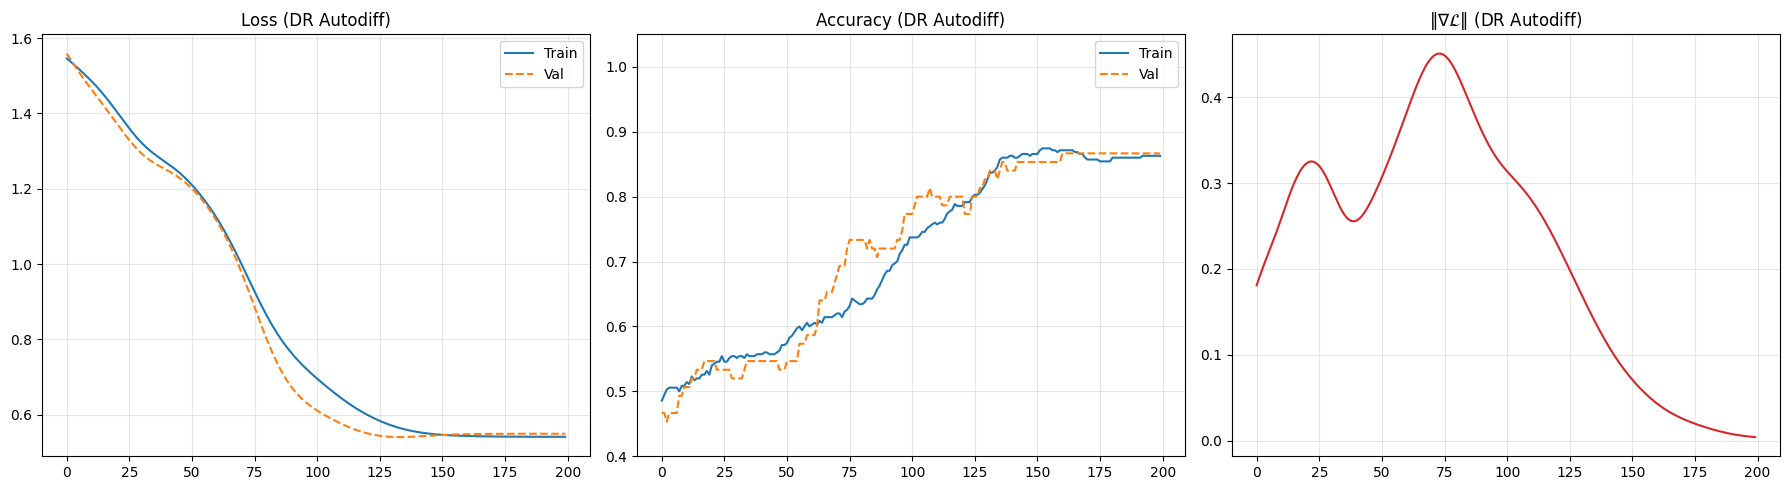

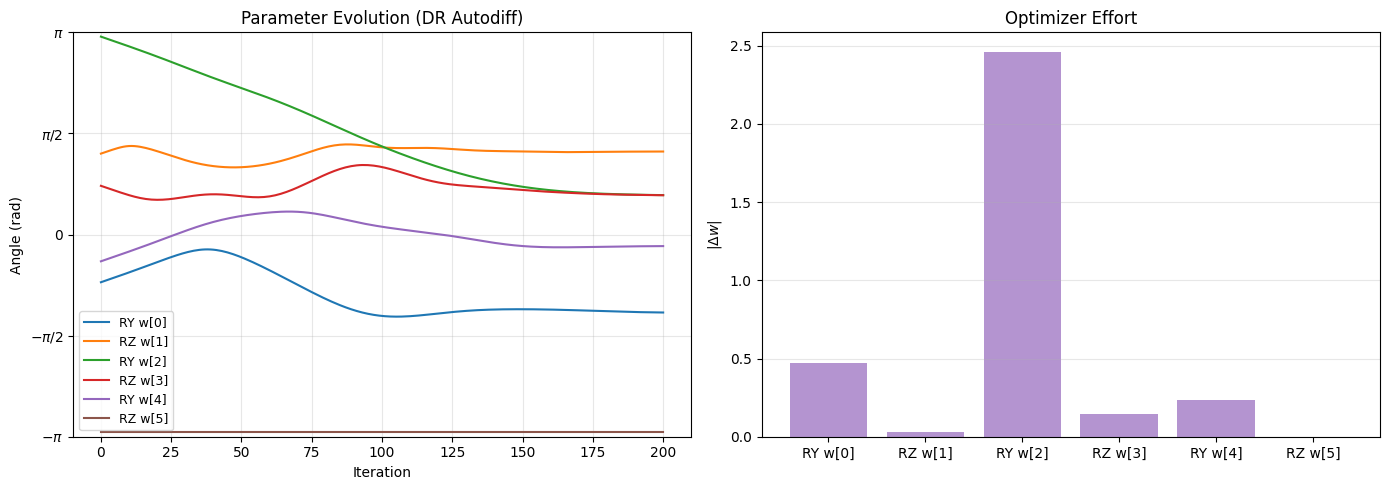

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(history_dr['train_loss'], label='Train', color='tab:blue')
axes[0].plot(history_dr['val_loss'], label='Val', color='tab:orange', linestyle='--')
axes[0].set_title('Loss (DR Autodiff)'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(history_dr['train_acc'], label='Train', color='tab:blue')
axes[1].plot(history_dr['val_acc'], label='Val', color='tab:orange', linestyle='--')
axes[1].set_title('Accuracy (DR Autodiff)'); axes[1].legend(); axes[1].grid(True, alpha=0.3); axes[1].set_ylim([0.4, 1.05])
axes[2].plot(history_dr['grad_norms'], color='tab:red')
axes[2].set_title('$\\|\\nabla \\mathcal{L}\\|$ (DR Autodiff)'); axes[2].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Parameter evolution
labels_dr = [f'RY w[{i}]' if i%2==0 else f'RZ w[{i}]' for i in range(nparams_dr)]
params_arr_dr = np.array(history_dr['params'])
params_arr_dr_w = np.mod(params_arr_dr + np.pi, 2*np.pi) - np.pi

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for k in range(nparams_dr): ax.plot(params_arr_dr_w[:, k], label=labels_dr[k], linewidth=1.5)
ax.set_title('Parameter Evolution (DR Autodiff)'); ax.set_xlabel('Iteration'); ax.set_ylabel('Angle (rad)')
ax.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
ax.set_yticklabels(['$-\\pi$', '$-\\pi/2$', '0', '$\\pi/2$', '$\\pi$']); ax.set_ylim([-np.pi, np.pi])
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
ax = axes[1]
delta_dr = np.abs(params_arr_dr[-1] - params_arr_dr[0])
ax.bar(range(nparams_dr), delta_dr, color='tab:purple', alpha=0.7, tick_label=labels_dr)
ax.set_title('Optimizer Effort'); ax.set_ylabel('$|\\Delta w|$'); ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

---
## 26. Decision Boundary — Data Reuploading (Autodiff)

Shown in **original scale** (grid passed through `process_data`). Points colored by model prediction.

[Qibo 0.2.23|INFO|2026-05-26 10:39:48]: Using numpy backend on /CPU:0


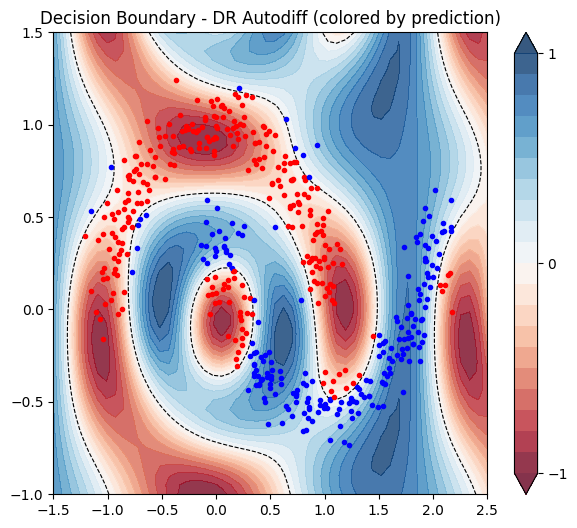

In [36]:
qibo.set_backend("numpy")  # fast numpy path

plt.figure(figsize=(7, 6))
xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 50), np.linspace(-1, 1.5, 50))
X_grid = np.stack([xx.flatten(), yy.flatten()], axis=1)
X_grid_proc = process_data(X_grid, ref_min=X_min, ref_max=X_max)

Z2 = fast_predict(params_np_dr, X_grid_proc, circuit_type='dr').reshape(xx.shape)
X_proc_all = process_data(X, ref_min=X_min, ref_max=X_max)
preds_all = fast_predict(params_np_dr, np.asarray(X_proc_all), circuit_type='dr')

cm = plt.cm.RdBu
cnt = plt.contourf(xx, yy, Z2, levels=np.arange(-1, 1.1, 0.1), cmap=cm, alpha=0.8, extend="both")
plt.contour(xx, yy, Z2, levels=[0.0], colors="black", linestyles="--", linewidths=0.8)
plt.colorbar(cnt, ticks=[-1, 0, 1])
for x_orig, pred in zip(X, preds_all):
    plt.plot(x_orig[0], x_orig[1], 'o', color='blue' if pred > 0 else 'red', markersize=3)
plt.title('Decision Boundary - DR Autodiff (colored by prediction)')
plt.savefig('figures/case1-dr-boundary.png', dpi=150, bbox_inches='tight'); plt.show()

---
## 27. Interactive Bloch Sphere — Data Reuploading (1 qubit)

With only **1 qubit**, the Bloch sphere is the complete picture — no partial trace needed.

**Left**: 3D sphere with stem lines to the equatorial plane for depth perception.

**Right**: 2D front projection (XZ plane). The vertical axis is exactly $\langle Z \rangle$: the model's prediction. Watch the two classes migrate toward opposite poles as training progresses.


In [37]:
qibo.set_backend("numpy")  # Bloch path bypasses qibo

# Pre-compute Bloch coordinates for every (iteration, sample). One batched
# numpy forward per iteration -- cheap.
print("Pre-computing Bloch sphere states (this populates the slider frames)...")
bloch_dr = precompute_bloch(history_dr['params'], X_bloch, nqubits_dr, circuit_type='dr')

# Self-contained Plotly viewer. All frame data is embedded in the figure JSON,
# so once this cell has been run the slider keeps working in the saved
# notebook (no kernel needed).
fig_bloch_dr = make_bloch_plotly(bloch_dr, Y_bloch, 1,
                                  suptitle="Bloch Sphere — Data Reuploading (slider scrubs training iteration)", height=520)
fig_bloch_dr.show()


[Qibo 0.2.23|INFO|2026-05-26 10:39:48]: Using numpy backend on /CPU:0


Pre-computing Bloch sphere states (this populates the slider frames)...
  Computing iteration 0/200...
  Computing iteration 50/200...
  Computing iteration 100/200...
  Computing iteration 150/200...
  Computing iteration 200/200...
  Done.


---
## 28. Data Reuploading — Parameter-Shift Training

Since encoding is **additive** ($w + x$), the standard $\pi/2$ shift is correct for all 6 parameters.

[Qibo 0.2.23|INFO|2026-05-26 10:39:48]: Using numpy backend on /CPU:0


SEED=0 RUN  (matches DR Autodiff seed=0 init for the methodology comparison)

Seed=0 PS:  final val_acc=0.8667  best val_acc=0.8400
Time: 0.01 min  |  Evals: 925,000

MULTI-SEED EXPLORATION
Multi-seed PS training [DR]: 8 seeds x 200 iter (dr)
  seed=0: final val_loss=0.5496 val_acc=0.8667  best (val_acc)=0.8667 (it 160)  time=0.4s
  seed=1: final val_loss=0.5486 val_acc=0.8800  best (val_acc)=0.8800 (it 193)  time=0.4s
  seed=2: final val_loss=0.5612 val_acc=0.8667  best (val_acc)=0.9333 (it  69)  time=0.4s
  seed=3: final val_loss=0.5500 val_acc=0.8667  best (val_acc)=0.8667 (it 122)  time=0.4s
  seed=4: final val_loss=0.7173 val_acc=0.7467  best (val_acc)=0.7733 (it  70)  time=0.4s
  seed=5: final val_loss=0.6050 val_acc=0.8667  best (val_acc)=0.8667 (it 199)  time=0.4s
  seed=6: final val_loss=0.5497 val_acc=0.8667  best (val_acc)=0.8667 (it 197)  time=0.4s
  seed=7: final val_loss=0.7494 val_acc=0.6933  best (val_acc)=0.6933 (it 157)  time=0.4s
-> Best: seed=2  best_val_acc=0.9333


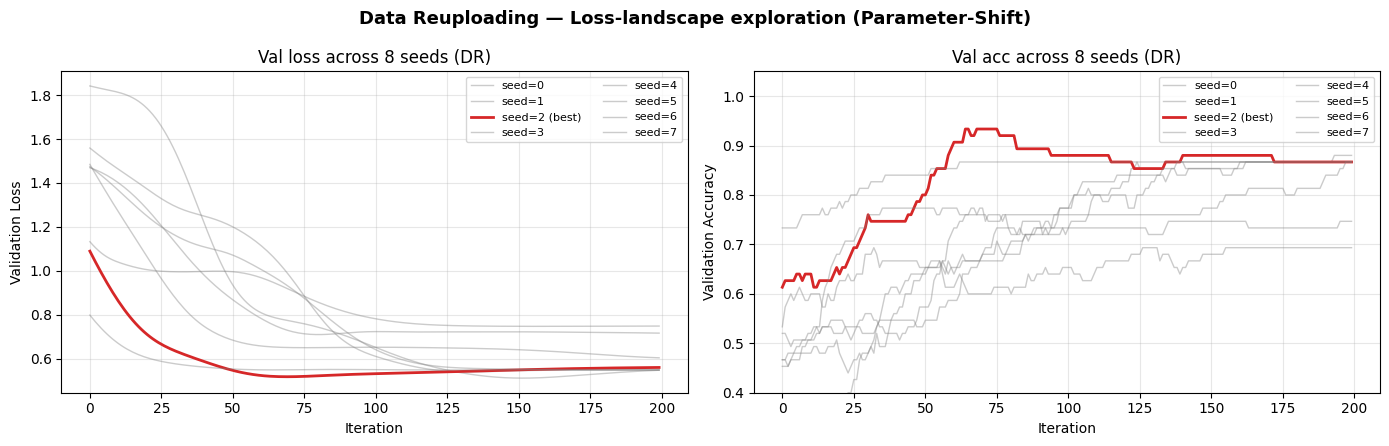

In [38]:
qibo.set_backend("numpy")  # PS path bypasses qibo

# === 1) seed=0 run for AD-vs-PS comparison ============================
print("=" * 70)
print("SEED=0 RUN  (matches DR Autodiff seed=0 init for the methodology comparison)")
print("=" * 70)
np.random.seed(0)
params_init_dr_seed0 = np.random.normal(0, 1, nparams_dr) * np.pi
reset_counter(); t0 = time()
history_dr_ps_seed0 = train_ps_run(params_init_dr_seed0, X_train_dr, Y_train_dr, X_val_dr, Y_val_dr,
    circuit_type='dr', n_iter=n_iter_dr, lr=0.015, store_param_history=True)
dr_ps_time = (time() - t0) / 60.0
dr_ps_evals = get_counter()
print(f"\nSeed=0 PS:  final val_acc={history_dr_ps_seed0['val_acc'][-1]:.4f}  "
      f"best val_acc={history_dr_ps_seed0['best_val_acc']:.4f}")
print(f"Time: {dr_ps_time:.2f} min  |  Evals: {dr_ps_evals:,}")

# === 2) Multi-seed exploration ========================================
print("\n" + "=" * 70)
print("MULTI-SEED EXPLORATION")
print("=" * 70)

def init_dr(seed, n_params):
    np.random.seed(seed)
    return np.random.normal(0, 1, n_params) * np.pi

n_seeds_dr = 8
best_run_dr, all_runs_dr = train_ps_multi_seed(list(range(n_seeds_dr)), nparams_dr, X_train_dr, Y_train_dr, X_val_dr, Y_val_dr,
    circuit_type='dr', init_fn=init_dr, n_iter=n_iter_dr, lr=0.015, label='DR', select_by='val_acc')

history_dr_ps = best_run_dr
params_dr_ps = best_run_dr['best_val_params']

print("\n-- Final cost (test, best multi-seed) --")
Cost_function_np(params_dr_ps, X_test_dr, Y_test_dr, nqubits_dr, circuit_type='dr')
total_evals_dr = sum(r['evals'] for r in all_runs_dr)
total_time_dr  = sum(r['time_s'] for r in all_runs_dr) / 60.0
print(f"Total multi-seed budget: {total_evals_dr:,} evals  |  {total_time_dr:.2f} min")

# Loss landscape
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for r in all_runs_dr:
    is_best = (r is best_run_dr)
    color = 'tab:red' if is_best else 'tab:gray'
    alpha = 1.0 if is_best else 0.4
    lw = 2.0 if is_best else 1.0
    label_ = f'seed={r["seed"]} (best)' if is_best else f'seed={r["seed"]}'
    axes[0].plot(r['val_loss'], color=color, alpha=alpha, linewidth=lw, label=label_)
    axes[1].plot(r['val_acc'],  color=color, alpha=alpha, linewidth=lw, label=label_)
axes[0].set_xlabel('Iteration'); axes[0].set_ylabel('Validation Loss')
axes[0].set_title(f'Val loss across {n_seeds_dr} seeds (DR)')
axes[0].grid(True, alpha=0.3); axes[0].legend(fontsize=8, ncol=2)
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('Validation Accuracy')
axes[1].set_title(f'Val acc across {n_seeds_dr} seeds (DR)')
axes[1].set_ylim([0.4, 1.05]); axes[1].grid(True, alpha=0.3); axes[1].legend(fontsize=8, ncol=2)
plt.suptitle('Data Reuploading — Loss-landscape exploration (Parameter-Shift)',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('figures/case1-dr-curves.png', dpi=150, bbox_inches='tight'); plt.show()


---
## 29. Decision Boundary — Data Reuploading (Parameter-Shift)

[Qibo 0.2.23|INFO|2026-05-26 10:39:52]: Using numpy backend on /CPU:0


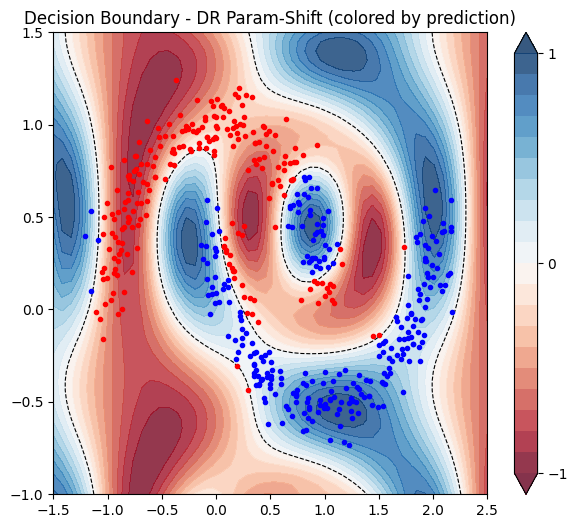

In [39]:
qibo.set_backend("numpy")  # PS/Bloch path bypasses qibo

plt.figure(figsize=(7, 6))
cm = plt.cm.RdBu
xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 50), np.linspace(-1, 1.5, 50))
X_grid = np.stack([xx.flatten(), yy.flatten()], axis=1)
X_grid_proc = process_data(X_grid, ref_min=X_min, ref_max=X_max)
preds_grid = fast_predict(params_dr_ps, X_grid_proc, circuit_type='dr')
Z2_ps = preds_grid.reshape(xx.shape)
cnt = plt.contourf(xx, yy, Z2_ps, levels=np.arange(-1, 1.1, 0.1), cmap=cm, alpha=0.8, extend="both")
plt.contour(xx, yy, Z2_ps, levels=[0.0], colors="black", linestyles="--", linewidths=0.8)
plt.colorbar(cnt, ticks=[-1, 0, 1])
X_proc_all = process_data(X, ref_min=X_min, ref_max=X_max)
preds_all = fast_predict(params_dr_ps, np.asarray(X_proc_all), circuit_type='dr')
for x_orig, pred in zip(X, preds_all):
    plt.plot(x_orig[0], x_orig[1], 'o', color='blue' if pred > 0 else 'red', markersize=3)
plt.title('Decision Boundary - DR Param-Shift (colored by prediction)'); plt.show()


---
## 30. Comparison: Autodiff vs Parameter-Shift (Data Reuploading)

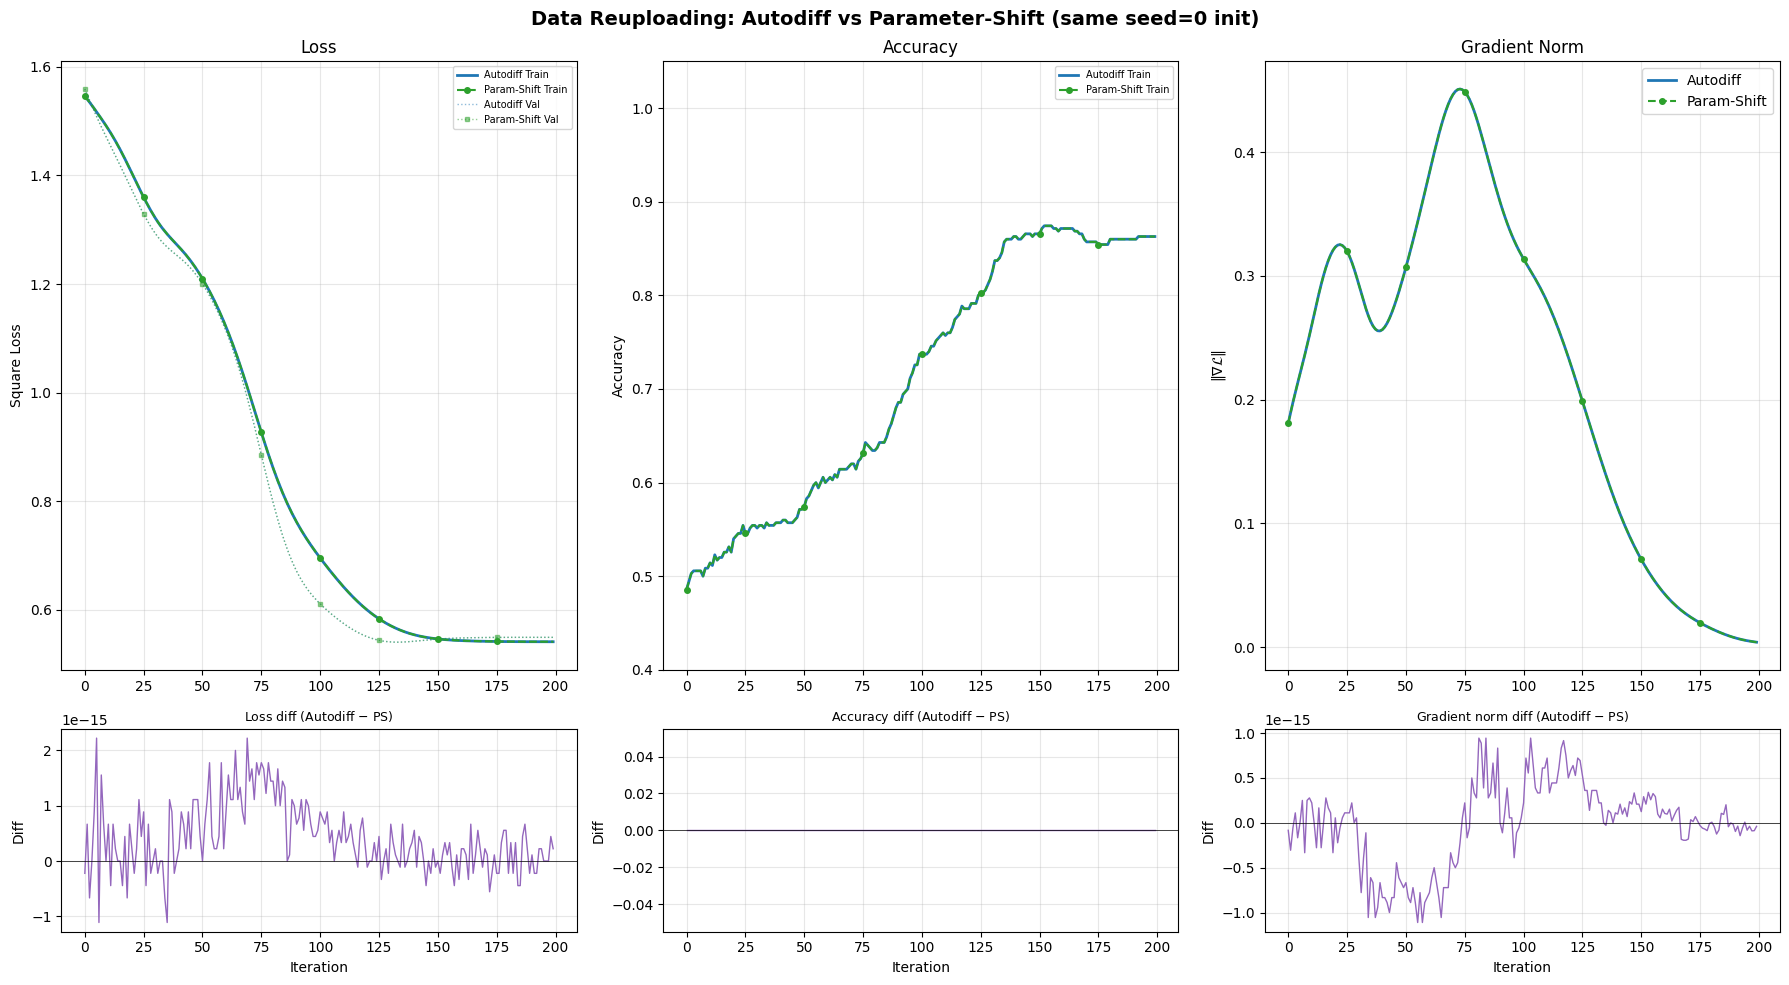

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), gridspec_kw={'height_ratios': [3, 1]})
mk_every = max(1, n_iter_dr // 8)

axes[0,0].plot(history_dr['train_loss'], label='Autodiff Train', color='tab:blue', linewidth=2)
axes[0,0].plot(history_dr_ps_seed0['train_loss'], label='Param-Shift Train', color='tab:green', linewidth=1.5, linestyle='--', marker='o', markevery=mk_every, markersize=4)
axes[0,0].plot(history_dr['val_loss'], label='Autodiff Val', color='tab:blue', linewidth=1, alpha=0.5, linestyle=':')
axes[0,0].plot(history_dr_ps_seed0['val_loss'], label='Param-Shift Val', color='tab:green', linewidth=1, alpha=0.5, linestyle=':', marker='s', markevery=mk_every, markersize=3)
axes[0,0].set_ylabel('Square Loss'); axes[0,0].set_title('Loss'); axes[0,0].legend(fontsize=7); axes[0,0].grid(True, alpha=0.3)

axes[0,1].plot(history_dr['train_acc'], label='Autodiff Train', color='tab:blue', linewidth=2)
axes[0,1].plot(history_dr_ps_seed0['train_acc'], label='Param-Shift Train', color='tab:green', linewidth=1.5, linestyle='--', marker='o', markevery=mk_every, markersize=4)
axes[0,1].set_ylabel('Accuracy'); axes[0,1].set_title('Accuracy'); axes[0,1].legend(fontsize=7)
axes[0,1].grid(True, alpha=0.3); axes[0,1].set_ylim([0.4, 1.05])

axes[0,2].plot(history_dr['grad_norms'], label='Autodiff', color='tab:blue', linewidth=2)
axes[0,2].plot(history_dr_ps_seed0['grad_norms'], label='Param-Shift', color='tab:green', linewidth=1.5, linestyle='--', marker='o', markevery=mk_every, markersize=4)
axes[0,2].set_ylabel('$\\|\\nabla \\mathcal{L}\\|$'); axes[0,2].set_title('Gradient Norm'); axes[0,2].legend(); axes[0,2].grid(True, alpha=0.3)

for col, (ad, ps, title) in enumerate([
    (history_dr['train_loss'], history_dr_ps_seed0['train_loss'], 'Loss diff'),
    (history_dr['train_acc'], history_dr_ps_seed0['train_acc'], 'Accuracy diff'),
    (history_dr['grad_norms'], history_dr_ps_seed0['grad_norms'], 'Gradient norm diff')]):
    diff = np.array(ad) - np.array(ps)
    axes[1,col].plot(diff, color='tab:purple', linewidth=1)
    axes[1,col].axhline(y=0, color='black', linewidth=0.5)
    axes[1,col].set_xlabel('Iteration'); axes[1,col].set_ylabel('Diff')
    axes[1,col].set_title(f'{title} (Autodiff $-$ PS)', fontsize=9); axes[1,col].grid(True, alpha=0.3)

plt.suptitle('Data Reuploading: Autodiff vs Parameter-Shift (same seed=0 init)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

---
---

## Summary

### Architecture Comparison

| Aspect | VQC Fixed Encoding | VQC Trainable Encoding | Data Reuploading |
|---|---|---|---|
| Qubits | 2 | 2 | 1 |
| Parameters | 18 | 22 | 6 |
| Layers | 4 | 4 | 3 |
| Encoding | Fixed ($x_j$) | Trainable ($w_k \cdot x_j$) | Additive ($w + x$) |
| Entanglement | Yes (CZ) | Yes (CZ) | No |
| Learning rate | 0.015 | 0.015 | 0.015 |

### Gradient Method Comparison

| Aspect | Autodifferentiation (PyTorch) | Parameter-Shift Rule |
|---|---|---|
| Works on real hardware? | **No** — needs internal state access | **Yes** — only runs the circuit |
| Gradient type | Exact (chain rule via backprop) | Exact (algebraic property of Pauli rotations) |
| Circuit evals per iteration | $N_{\text{train}} + N_{\text{val}}$ | $N_{\text{train}} \times (1 + 2 n_{\text{params}}) + N_{\text{val}}$ |
| Eval cost multiplier vs autodiff | 1x | ~$2 \times n_{\text{params}}$x |
| Dependency | PyTorch (GPU-accelerable) | Pure NumPy |

### Fixed vs Trainable Encoding

| Aspect | Fixed Encoding | Trainable Encoding |
|---|---|---|
| Encoding formula | $\theta = x_j$ (data injected directly) | $\theta = w_k \cdot x_j$ (learnable scaling) |
| Encoding parameters | 0 | 4 |
| Advantage | Simple, standard approach | Learns optimal feature scaling |
| When to use | Well-preprocessed data | Unknown feature importance or scales |

### Bloch Sphere Insights

The interactive Bloch sphere visualizations reveal:
- **Before training**: data points from both classes are scattered without separation.
- **After training**: classes cluster near opposite poles ($|0\rangle$ for +1, $|1\rangle$ for $-1$), corresponding to positive/negative $\langle Z \rangle$.
- **1-qubit (DR)**: the Bloch sphere completely describes the qubit state. The $z$-coordinate is exactly $\langle Z \rangle$.
- **2-qubit (VQC)**: the partial trace reveals the effective single-qubit behavior. Qubit 0 (measured) shows class separation; qubit 1 (ancilla) shows its role in assisting the computation through entanglement.

### Key Questions for Analysis

1. **Do the parameters converge?** Do they stabilize or keep changing?
2. **Are some parameters more important?** Largest $|\Delta w|$ indicates biggest impact.
3. **Fixed vs trainable encoding**: Does training the encoding improve accuracy? By how much?
4. **Barren plateau signs?** Gradient norm collapsing to zero.
5. **Bloch sphere separation**: How cleanly do the classes separate on the sphere?
6. **Autodiff vs parameter-shift**: Matching curves confirm both methods compute exact, identical gradients.

---

## Final Summary — Multi-Architecture Comparison (Multi-seed Best)

The table below summarises the three architectures using the **best-by-validation
checkpoint of the best seed** from the multi-seed exploration. This is the honest
"best result we found within the compute budget allocated".

For each architecture: 8 seeds × 200 iterations of parameter-shift training, with
within-run best-by-val checkpoint tracking (early-stop equivalent). Test-set
metrics are reported on a held-out partition not used for training or validation.


FINAL SUMMARY — best-by-validation checkpoint, best of 8 seeds
Architecture      Params  Best seed  Best @iter  Train loss (best)  Train acc  (best)  Val   loss (best)  Val   acc  (best)  Test  loss  Test  acc
--------------------------------------------------------------------------------------------------------------
Fixed VQC         18      3          50          0.6091             0.8371             0.6494             0.8800             0.5895      0.8133   
Trainable VQC     22      6          122         0.2823             0.9457             0.3657             0.9333             0.2914      0.9333   
Data Reuploading  6       2          69          0.6367             0.8200             0.5190             0.9333             0.5597      0.8933   

Compute budget (multi-seed PS, all architectures):
  Fixed VQC     :    20,840,000 evals     0.89 min
  Trainable VQC :    25,320,000 evals     1.15 min
  DR            :     7,400,000 evals     0.06 min


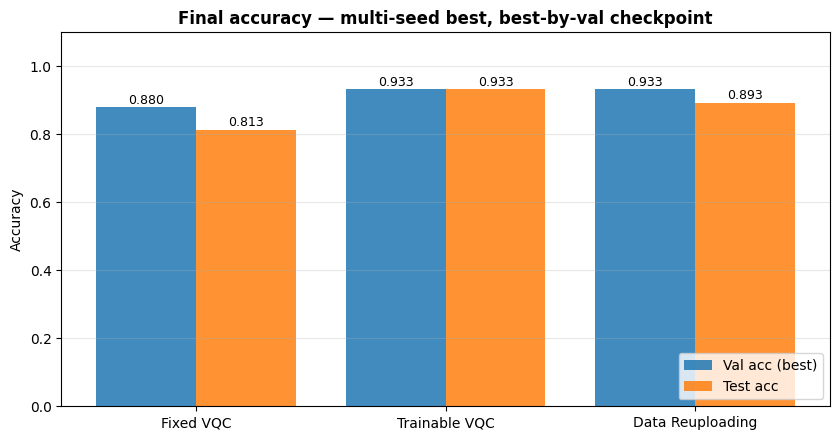

In [41]:
# Multi-architecture summary table (using multi-seed best results)
rows = []
for label, run, ct, X_te, Y_te, nq, n_par in [
    ('Fixed VQC',        best_run_fixed, 'fixed',     X_test,    Y_test,    nqubits,    nparams_fixed),
    ('Trainable VQC',    best_run_te,    'trainable', X_test,    Y_test,    nqubits,    nparams_train),
    ('Data Reuploading', best_run_dr,    'dr',        X_test_dr, Y_test_dr, nqubits_dr, nparams_dr)]:
    test_loss, test_acc = Cost_function_np(run['best_val_params'], X_te, Y_te, nq,
                                            circuit_type=ct, verbose=False)
    rows.append({
        'Architecture':       label,
        'Params':             n_par,
        'Best seed':          run['seed'],
        'Best @iter':         run['best_val_iter'],
        'Train loss (best)':  f"{run['train_loss'][run['best_val_iter']]:.4f}",
        'Train acc  (best)':  f"{run['train_acc'][run['best_val_iter']]:.4f}",
        'Val   loss (best)':  f"{run['best_val_loss']:.4f}",
        'Val   acc  (best)':  f"{run['best_val_acc']:.4f}",
        'Test  loss':         f"{test_loss:.4f}",
        'Test  acc':          f"{test_acc:.4f}",
    })

print('=' * 110)
print('FINAL SUMMARY — best-by-validation checkpoint, best of 8 seeds')
print('=' * 110)
header = list(rows[0].keys())
widths = {k: max(len(k), max(len(str(r[k])) for r in rows)) for k in header}
fmt = '  '.join(f'{{:<{widths[k]}}}' for k in header)
print(fmt.format(*header))
print('-' * 110)
for r in rows:
    print(fmt.format(*[str(r[k]) for k in header]))
print('=' * 110)

print()
print('Compute budget (multi-seed PS, all architectures):')
print(f'  Fixed VQC     : {sum(r["evals"]   for r in all_runs_fixed):>13,} evals   '
      f'{sum(r["time_s"] for r in all_runs_fixed)/60:6.2f} min')
print(f'  Trainable VQC : {sum(r["evals"]   for r in all_runs_te):>13,} evals   '
      f'{sum(r["time_s"] for r in all_runs_te)/60:6.2f} min')
print(f'  DR            : {sum(r["evals"]   for r in all_runs_dr):>13,} evals   '
      f'{sum(r["time_s"] for r in all_runs_dr)/60:6.2f} min')

# Bar chart: best-val and test acc per architecture
fig, ax = plt.subplots(figsize=(8.5, 4.5))
arch_names = [r['Architecture'] for r in rows]
val_accs   = [float(r['Val   acc  (best)']) for r in rows]
test_accs  = [float(r['Test  acc'])         for r in rows]
x = np.arange(len(arch_names))
ax.bar(x - 0.2, val_accs,  width=0.4, label='Val acc (best)', color='tab:blue',   alpha=0.85)
ax.bar(x + 0.2, test_accs, width=0.4, label='Test acc',       color='tab:orange', alpha=0.85)
for xi, va, ta in zip(x, val_accs, test_accs):
    ax.text(xi - 0.2, va + 0.01, f'{va:.3f}', ha='center', fontsize=9)
    ax.text(xi + 0.2, ta + 0.01, f'{ta:.3f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(arch_names)
ax.set_ylabel('Accuracy'); ax.set_ylim([0, 1.1])
ax.set_title('Final accuracy — multi-seed best, best-by-val checkpoint',
             fontsize=12, fontweight='bold')
ax.legend(loc='lower right'); ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout(); plt.savefig('figures/case1-final-bars.png', dpi=150, bbox_inches='tight'); plt.show()


## Case I validation — reproducing a published reference and selecting qubits and layers

This section validates the framework's VQC against the data re-uploading QNN of
Rodriguez-Grasa, Ban & Sanz (arXiv:2401.04642), on two balanced datasets from
their Appendix E.1 (corners and circles). The heavy parameter sweep is run once
by `run_validation.py` (the analogue of `run_annex.py`) and cached in
`results/case1_validation.json`; the cells below load that cache and render the
figures and comparison tables, so a full "Run All" stays fast.

- **Layer sweep** (n = 2 qubits, L = 1..8) is compared with the reference's Table IV.
- **Qubit sweep** (L = 7 layers, n = 1..4) is compared with the reference's Table III.

The framework reproduces the reference closely on corners and exceeds it on
circles; from the plateau of accuracy in both sweeps, **n = 2 qubits and L = 5
layers** is selected for Case II.

Validation config: {'datasets': ['corners', 'circles'], 'noise': 0.02, 'n_samples': 2000, 'n_train': 400, 'n_val': 200, 'n_test': 300, 'seeds': [0, 1, 2], 'iters': 120, 'lr': 0.05, 'rot': 'su2', 'entangle': 'cz', 'init': 'pi_uniform', 'qubit_sweep_layers': 7}


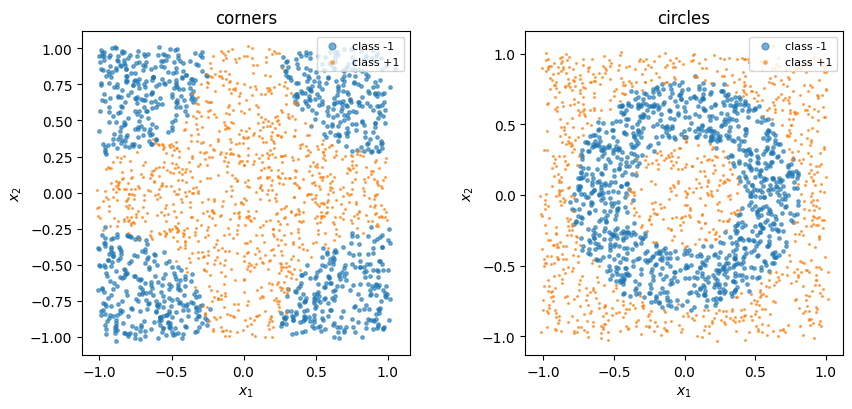

In [2]:
# --- Case I validation: load the precomputed sweep cache -------------------
# Heavy compute lives in run_validation.py (analogous to run_annex.py); this
# notebook just loads results/case1_validation.json and renders the figures and
# comparison tables, so "Run All" stays fast.
import json
import numpy as np
import matplotlib.pyplot as plt
import toy_datasets as td

with open('results/case1_validation.json') as f:
    VAL = json.load(f)
# JSON stringifies integer keys; coerce the paper reference tables back to int.
for _tbl in ('table_iv_n2', 'table_iii_byqubits'):
    VAL['paper'][_tbl] = {ds: {int(k): v for k, v in vals.items()}
                          for ds, vals in VAL['paper'][_tbl].items()}
RUNS = VAL['runs']
PAPER = VAL['paper']
DSETS = VAL['config']['datasets']
NOISE = VAL['config']['noise']
print('Validation config:', VAL['config'])

# The two balanced reference datasets (corners, circles).
fig, axes = plt.subplots(1, len(DSETS), figsize=(9, 4.2))
for ax, name in zip(np.atleast_1d(axes), DSETS):
    X, y = td.make_dataset(name, n_samples=2000, noise=NOISE, random_state=42)
    for c, m, lbl in [(0, 'o', 'class -1'), (1, '.', 'class +1')]:
        ax.scatter(X[y == c, 0], X[y == c, 1], s=6, marker=m, alpha=0.6, label=lbl)
    ax.set_title(name); ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
    ax.set_aspect('equal'); ax.legend(markerscale=2, fontsize=8, loc='upper right')
fig.tight_layout()
fig.savefig('figures/case1-val-datasets.png', dpi=150, bbox_inches='tight')
plt.show()

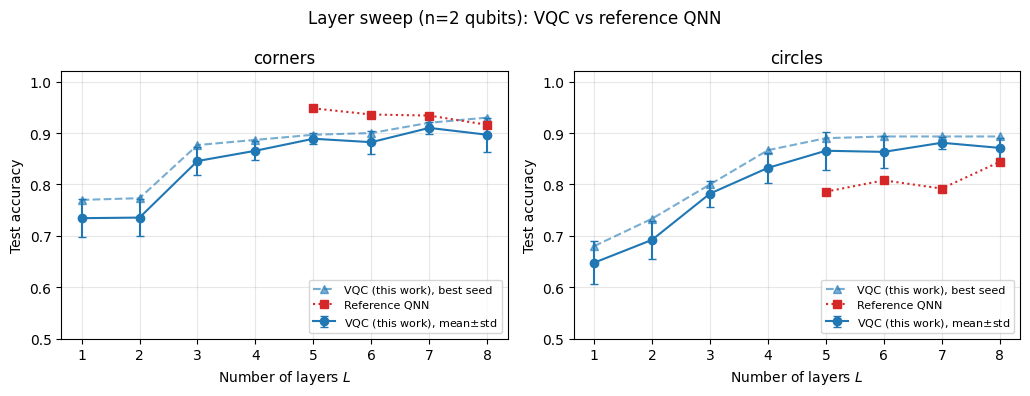

 dataset   L  ours mean  ours best   paper     diff
 corners   1      0.734      0.770     -        -  
 corners   2      0.736      0.773     -        -  
 corners   3      0.846      0.877     -        -  
 corners   4      0.866      0.887     -        -  
 corners   5      0.889      0.897   0.948   -0.051
 corners   6      0.882      0.900   0.936   -0.036
 corners   7      0.910      0.920   0.934   -0.014
 corners   8      0.897      0.930   0.916   +0.014
 circles   1      0.648      0.680     -        -  
 circles   2      0.692      0.733     -        -  
 circles   3      0.782      0.800     -        -  
 circles   4      0.832      0.867     -        -  
 circles   5      0.866      0.890   0.786   +0.104
 circles   6      0.863      0.893   0.808   +0.085
 circles   7      0.881      0.893   0.792   +0.101
 circles   8      0.871      0.893   0.844   +0.049


In [3]:
# --- Layer sweep (n=2 qubits) vs reference Table IV ------------------------
def _curve(kind, key, name):
    rs = [r for r in RUNS if r['kind'] == kind and r['dataset'] == name]
    return sorted(rs, key=lambda r: r[key])

fig, axes = plt.subplots(1, len(DSETS), figsize=(5.2 * len(DSETS), 4.0), squeeze=False)
for ax, name in zip(axes[0], DSETS):
    rs = _curve('layer_sweep', 'n_layers', name)
    xs = [r['n_layers'] for r in rs]
    ax.errorbar(xs, [r['test_acc_mean'] for r in rs],
                yerr=[r['test_acc_std'] for r in rs], marker='o', capsize=3,
                color='C0', label='VQC (this work), mean$\\pm$std')
    ax.plot(xs, [r['test_acc_best'] for r in rs], marker='^', ls='--',
            color='C0', alpha=0.6, label='VQC (this work), best seed')
    pd = PAPER['table_iv_n2'].get(name, {})
    px = sorted(pd)
    ax.plot(px, [pd[k] for k in px], marker='s', ls=':', color='C3',
            label='Reference QNN')
    ax.set_title(name); ax.set_xlabel('Number of layers $L$')
    ax.set_ylabel('Test accuracy'); ax.set_ylim(0.5, 1.02); ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='lower right')
fig.suptitle('Layer sweep (n=2 qubits): VQC vs reference QNN')
fig.tight_layout()
fig.savefig('figures/case1-val-layers.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"{'dataset':>8} {'L':>3} {'ours mean':>10} {'ours best':>10} {'paper':>7} {'diff':>8}")
for r in [r for r in RUNS if r['kind'] == 'layer_sweep']:
    p = PAPER['table_iv_n2'].get(r['dataset'], {}).get(r['n_layers'])
    ref = f"{p:.3f}" if p else "  -  "
    diff = f"{r['test_acc_best'] - p:+.3f}" if p else "  -  "
    print(f"{r['dataset']:>8} {r['n_layers']:>3} {r['test_acc_mean']:>10.3f} "
          f"{r['test_acc_best']:>10.3f} {ref:>7} {diff:>8}")

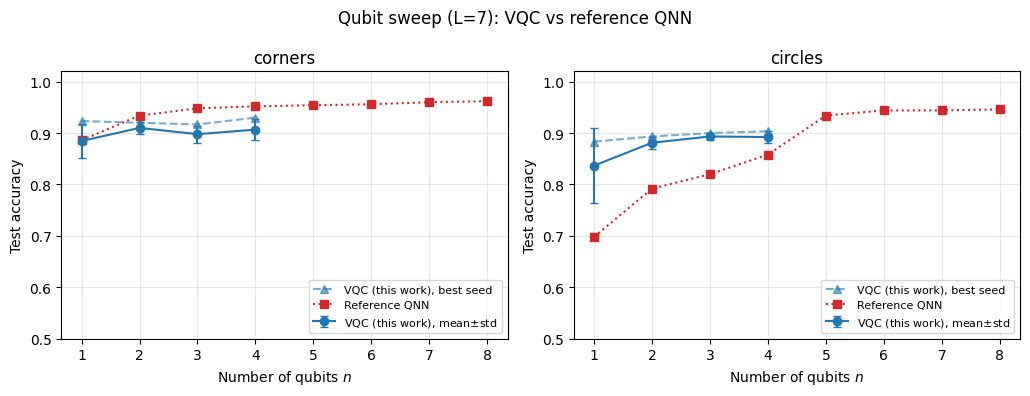

 dataset   n  ours mean  ours best   paper     diff
 corners   1      0.884      0.923   0.886   +0.037
 corners   2      0.910      0.920   0.934   -0.014
 corners   3      0.898      0.917   0.948   -0.031
 corners   4      0.907      0.930   0.952   -0.022
 circles   1      0.837      0.883   0.698   +0.185
 circles   2      0.881      0.893   0.792   +0.101
 circles   3      0.893      0.900   0.820   +0.080
 circles   4      0.892      0.903   0.858   +0.045


In [4]:
# --- Qubit sweep (L=7 layers) vs reference Table III ----------------------
fig, axes = plt.subplots(1, len(DSETS), figsize=(5.2 * len(DSETS), 4.0), squeeze=False)
for ax, name in zip(axes[0], DSETS):
    rs = _curve('qubit_sweep', 'n_qubits', name)
    xs = [r['n_qubits'] for r in rs]
    ax.errorbar(xs, [r['test_acc_mean'] for r in rs],
                yerr=[r['test_acc_std'] for r in rs], marker='o', capsize=3,
                color='C0', label='VQC (this work), mean$\\pm$std')
    ax.plot(xs, [r['test_acc_best'] for r in rs], marker='^', ls='--',
            color='C0', alpha=0.6, label='VQC (this work), best seed')
    pd = PAPER['table_iii_byqubits'].get(name, {})
    px = sorted(pd)
    ax.plot(px, [pd[k] for k in px], marker='s', ls=':', color='C3',
            label='Reference QNN')
    ax.set_title(name); ax.set_xlabel('Number of qubits $n$')
    ax.set_ylabel('Test accuracy'); ax.set_ylim(0.5, 1.02); ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='lower right')
fig.suptitle('Qubit sweep (L=7): VQC vs reference QNN')
fig.tight_layout()
fig.savefig('figures/case1-val-qubits.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"{'dataset':>8} {'n':>3} {'ours mean':>10} {'ours best':>10} {'paper':>7} {'diff':>8}")
for r in [r for r in RUNS if r['kind'] == 'qubit_sweep']:
    p = PAPER['table_iii_byqubits'].get(r['dataset'], {}).get(r['n_qubits'])
    ref = f"{p:.3f}" if p else "  -  "
    diff = f"{r['test_acc_best'] - p:+.3f}" if p else "  -  "
    print(f"{r['dataset']:>8} {r['n_qubits']:>3} {r['test_acc_mean']:>10.3f} "
          f"{r['test_acc_best']:>10.3f} {ref:>7} {diff:>8}")

**Selected configuration.** Accuracy is already near its maximum at two qubits
and reaches a plateau from about five layers onward, so Case II uses two-qubit
circuits with a layer count in this region. The encoding contrast in the cache
(`kind == "encoding_cmp"`) further shows that re-uploading the data at every
layer is markedly stronger than encoding it once, consistent with including a
data-reuploading model among the Case II architectures.